# PathQC-Triage: WSI Artifact Detection and Tissue Anomaly Scoring Pipeline

**End-to-End Computational Pathology Pipeline for Quality Control and Self-Supervised Anomaly Detection**

This notebook implements a two-stage histopathology pipeline that mirrors industrial automated slide triage workflows (such as AIRA Matrix's AIRAQc and AIRATox production modules):
1. **Stage 1 (Artifact Quality Control):** MobileNetV3-Small classifier trained on PathMNIST (the lightweight, standardized 9-class benchmark derived from NCT-CRC-HE-100K) with spatial heatmap generation and automated slide usability scoring.
2. **Stage 2 (Self-Supervised Tissue Anomaly Scoring):** SimCLR contrastive representation learning on normal tissue patches combined with an Isolation Forest detector that flags morphological anomalies (tumors) without requiring pixel-level annotations.


### Cell 1: Environment Setup and Package Installation
We install dependencies required for deep learning, computer vision, metric calculation, self-supervised learning, and dataset loading.
We use `medmnist` to load **PathMNIST** (~33 MB total download, derived directly from NCT-CRC-HE-100K) so the entire notebook runs fast with zero dataset download bottlenecks.


In [24]:
# Cell 1: Install required libraries for Stage 1 (QC) and Stage 2 (SSL Anomaly Detection)
!pip install -q torch torchvision timm scikit-learn matplotlib seaborn Pillow numpy tqdm opencv-python-headless lightly medmnist

import torch
import torchvision
import numpy as np
import matplotlib.pyplot as plt
import os
from pathlib import Path
import medmnist
from medmnist import INFO, PathMNIST
# Save every checkpoint and visualization beside this notebook.
# When launched from the project folder, this is the pathqc directory.
OUTPUT_DIR = Path.cwd()
if not (OUTPUT_DIR / "PathQC_Triage.ipynb").exists() and (OUTPUT_DIR / "pathqc" / "PathQC_Triage.ipynb").exists():
    OUTPUT_DIR = OUTPUT_DIR / "pathqc"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Outputs will be saved to: {OUTPUT_DIR.resolve()}")

# Verify device availability for Colab execution
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Compute device selected: {device}")
if torch.cuda.is_available():
    print(f"GPU device name: {torch.cuda.get_device_name(0)}")

print("All packages installed")




Outputs will be saved to: /content
Compute device selected: cuda
GPU device name: Tesla T4
All packages installed


### Cell 2: Stage 1 Overview - Whole Slide Image Artifact Detection

#### 1. What WSI Artifact Detection Is and Why It Matters
Whole Slide Imaging (WSI) digitizes glass histopathology specimens at high magnifications (20x-40x), producing gigapixel images. During pre-analytical slide preparation, microtome sectioning, and scanning, several physical artifacts frequently occur:
- **Tissue folds and tears** (compressed or overlapping tissue during floatation)
- **Cover slip debris, dust, and air bubbles**
- **Out-of-focus blur and staining inconsistencies**
- **Vast empty glass backgrounds**

If these corrupted or non-tissue regions are fed directly into downstream diagnostic AI models (e.g., cancer grading, biomarker prediction), the models produce severe false positives or hallucinations. Automated quality control flags or rejects artifact-heavy tiles upfront, preventing wasted compute and clinical errors.

#### 2. Why We Use the PathMNIST Dataset
**PathMNIST** is the official lightweight benchmark derived directly from **NCT-CRC-HE-100K** (Kather et al.). It packages the exact same 9 clinical tissue and artifact classes into an efficient format (~33 MB total archive) that downloads automatically in seconds:
- **Train split:** 89,996 images
- **Validation split:** 10,004 images
- **Test split:** 7,180 images

#### 3. The 9 Tissue and Artifact Classes
0. `ADI`: Adipose tissue (fat globules)
1. `BACK`: Background (glass slide, non-tissue, mounting medium) - **Artifact class**
2. `DEB`: Debris (dust, dirt, dye crystals, necrotic fragmentation) - **Artifact class**
3. `LYM`: Lymphocytes (immune cells and aggregates)
4. `MUC`: Mucus (acellular secretion lakes)
5. `MUS`: Smooth muscle (myosin bundles; prone to section folds)
6. `NORM`: Normal colon mucosa - **Healthy tissue class (used in Stage 2)**
7. `STR`: Cancer-associated stroma (fibroblasts, connective tissue)
8. `TUM`: Colorectal adenocarcinoma epithelium - **Tumor / Anomaly class**

#### 4. What Our Model Will Do
We train a lightweight, real-time **MobileNetV3-Small** architecture to classify all 9 classes. We retain all 9 categories so the network learns the full morphologic spectrum of histopathology rather than collapsing into a naive binary heuristic. Then, we assemble patch predictions into a spatial artifact heatmap and compute an automated **Slide Usability Score**.


### Cell 3: Dataset Ingestion - PathMNIST
We load PathMNIST directly using `medmnist.PathMNIST` with `download=True`. The entire dataset (~33 MB) downloads in seconds, avoiding multi-gigabyte archive extractions and disk exhaustion.


In [25]:
# Cell 3: Download and inspect PathMNIST
import medmnist
from medmnist import INFO, PathMNIST

data_flag = 'pathmnist'
info = INFO[data_flag]
class_names = [info['label'][str(i)] for i in range(len(info['label']))]
class_abbrevs = ["ADI", "BACK", "DEB", "LYM", "MUC", "MUS", "NORM", "STR", "TUM"]

print(f"Dataset name: {info['python_class']}")
print(f"Number of classes: {len(class_names)}")
print("\nClass mapping:")
for i in range(len(class_names)):
    print(f"  Class {i} ({class_abbrevs[i]}): {class_names[i]}")

# Download train, validation, and test splits
print("\nDownloading PathMNIST splits (approx 33 MB total)...")
raw_train_dataset = PathMNIST(split="train", download=True)
raw_val_dataset   = PathMNIST(split="val", download=True)
raw_test_dataset  = PathMNIST(split="test", download=True)

print(f"Train split:      {len(raw_train_dataset):,} patches")
print(f"Validation split: {len(raw_val_dataset):,} patches")
print(f"Test split:       {len(raw_test_dataset):,} patches")
print("Dataset ready.")



Dataset name: PathMNIST
Number of classes: 9

Class mapping:
  Class 0 (ADI): adipose
  Class 1 (BACK): background
  Class 2 (DEB): debris
  Class 3 (LYM): lymphocytes
  Class 4 (MUC): mucus
  Class 5 (MUS): smooth muscle
  Class 6 (NORM): normal colon mucosa
  Class 7 (STR): cancer-associated stroma
  Class 8 (TUM): colorectal adenocarcinoma epithelium

Train split:      89,996 patches
Validation split: 10,004 patches
Test split:       7,180 patches
Dataset ready.


### Cell 4: PyTorch DataLoaders and Augmentations
Histopathology slides have no canonical orientation: 90-degree rotations and vertical/horizontal flips simulate physical orientation invariances. Color jitter simulates variability in hematoxylin and eosin (H&E) staining protocols.

To maintain fast execution on Colab, we sample a balanced training subset of 18,000 images (2,000 per class) and 4,500 validation images (500 per class) with a reproducible seed (`seed=42`).


In [26]:
# Cell 4: Reproducible, balanced data loaders
import random
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)

train_transforms = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation((0, 90)),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])
val_transforms = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

class PathQCWrapperDataset(Dataset):
    def __init__(self, medmnist_dataset, indices, transform=None):
        self.dataset = medmnist_dataset
        self.indices = list(indices)
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        image, label = self.dataset[self.indices[idx]]
        if not isinstance(image, Image.Image):
            image = Image.fromarray(np.asarray(image))
        image = image.convert("RGB")
        if self.transform is not None:
            image = self.transform(image)
        return image, int(np.asarray(label).reshape(-1)[0])

def get_balanced_indices(dataset, samples_per_class=None, seed=SEED):
    labels = np.asarray(dataset.labels).reshape(-1).astype(int)
    rng = random.Random(seed)
    class_to_indices = {}
    for index, label in enumerate(labels):
        class_to_indices.setdefault(int(label), []).append(index)
    selected = []
    for indices in class_to_indices.values():
        count = len(indices) if samples_per_class is None else min(samples_per_class, len(indices))
        selected.extend(rng.sample(indices, count))
    rng.shuffle(selected)
    return selected

train_indices = get_balanced_indices(raw_train_dataset, samples_per_class=3000)
val_indices = get_balanced_indices(raw_val_dataset, samples_per_class=750)
train_dataset = PathQCWrapperDataset(raw_train_dataset, train_indices, train_transforms)
val_dataset = PathQCWrapperDataset(raw_val_dataset, val_indices, val_transforms)

loader_kwargs = {"batch_size": 128, "num_workers": 0, "pin_memory": torch.cuda.is_available()}
train_loader = DataLoader(train_dataset, shuffle=True, **loader_kwargs)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_kwargs)
print(f"Training set: {len(train_dataset):,}; validation set: {len(val_dataset):,}")


Training set: 27,000; validation set: 6,750


### Cell 5: Stage 1 Architecture - Lightweight MobileNetV3-Small
In clinical pathology pipelines, a whole slide image contains 10,000 to 50,000 individual tiles. Processing times must remain near real-time. Hence, heavy vision transformers or deep ResNets are impractical for upfront quality control triage.

We employ **MobileNetV3-Small** with pretrained ImageNet weights. We freeze the feature extraction backbone and replace the classifier head with:
$$\text{Linear}(576 \to 256) \to \text{Hardswish} \to \text{Dropout}(0.2) \to \text{Linear}(256 \to 9)$$
This yields an ultra-fast, high-accuracy inference engine with low memory footprint.


In [27]:
# Cell 5: MobileNetV3 with partial backbone fine-tuning
import torch.nn as nn
import torchvision.models as models

def create_artifact_classifier(num_classes=9, unfreeze_last_blocks=3):
    weights = models.MobileNet_V3_Small_Weights.DEFAULT
    model = models.mobilenet_v3_small(weights=weights)
    for parameter in model.features.parameters():
        parameter.requires_grad = False
    for block in list(model.features.children())[-unfreeze_last_blocks:]:
        for parameter in block.parameters():
            parameter.requires_grad = True
    in_features = model.classifier[0].in_features
    model.classifier = nn.Sequential(
        nn.Linear(in_features, 256),
        nn.Hardswish(),
        nn.Dropout(0.25),
        nn.Linear(256, num_classes),
    )
    return model

qc_model = create_artifact_classifier(num_classes=len(class_abbrevs)).to(device)
total_params = sum(p.numel() for p in qc_model.parameters())
trainable_params = sum(p.numel() for p in qc_model.parameters() if p.requires_grad)
print(f"Trainable parameters: {trainable_params:,}/{total_params:,} ({trainable_params/total_params:.1%})")


Trainable parameters: 794,665/1,077,033 (73.8%)


### Cell 6: Training and Validation Pipeline
We train the classifier for 15 epochs using:
- **Optimizer:** Adam with learning rate $1 \times 10^{-3}$
- **Criterion:** CrossEntropyLoss
- **Scheduler:** ReduceLROnPlateau (monitoring validation loss, patience=3, factor=0.5)
- **Model Checkpointing:** Saves model weights to `best_artifact_model.pth` whenever validation accuracy achieves a new peak.


In [28]:
# Cell 6: Efficient training with AMP, macro-F1 checkpoints, and early stopping
import time
from sklearn.metrics import f1_score

criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
head_parameters = list(qc_model.classifier.parameters())
backbone_parameters = [
    parameter for name, parameter in qc_model.named_parameters()
    if parameter.requires_grad and not name.startswith("classifier.")
]
optimizer = torch.optim.AdamW([
    {"params": head_parameters, "lr": 3e-4},
    {"params": backbone_parameters, "lr": 3e-5},
], weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=2
)
amp_enabled = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=amp_enabled)

def run_epoch(model, dataloader, training):
    model.train(training)
    losses, predictions, targets_seen = [], [], []
    for images, labels in dataloader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        if training:
            optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp_enabled):
            outputs = model(images)
            loss = criterion(outputs, labels)
        if training:
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        losses.append(loss.detach().item() * labels.size(0))
        predictions.append(outputs.detach().argmax(1).cpu().numpy())
        targets_seen.append(labels.cpu().numpy())
    y_pred = np.concatenate(predictions)
    y_true = np.concatenate(targets_seen)
    return sum(losses) / len(y_true), f1_score(y_true, y_pred, average="macro", zero_division=0)

history = {"train_loss": [], "train_f1": [], "val_loss": [], "val_f1": []}
num_epochs, patience, stale_epochs = 20, 5, 0
best_val_f1 = -1.0
checkpoint_path = OUTPUT_DIR / "best_artifact_model.pth"

for epoch in range(num_epochs):
    start = time.time()
    train_loss, train_f1 = run_epoch(qc_model, train_loader, training=True)
    with torch.no_grad():
        val_loss, val_f1 = run_epoch(qc_model, val_loader, training=False)
    scheduler.step(val_f1)
    history["train_loss"].append(train_loss)
    history["train_f1"].append(train_f1)
    history["val_loss"].append(val_loss)
    history["val_f1"].append(val_f1)
    if val_f1 > best_val_f1:
        best_val_f1, stale_epochs = val_f1, 0
        torch.save({
            "model_state": qc_model.state_dict(),
            "optimizer_state": optimizer.state_dict(),
            "epoch": epoch,
            "val_macro_f1": val_f1,
            "class_names": class_abbrevs,
        }, checkpoint_path)
        marker = " [checkpoint]"
    else:
        stale_epochs += 1
        marker = ""
    print(f"Epoch {epoch+1:02d}/{num_epochs} | train F1 {train_f1:.4f} | "
          f"val F1 {val_f1:.4f} | {time.time()-start:.1f}s{marker}")
    if stale_epochs >= patience:
        print("Early stopping: validation macro-F1 did not improve.")
        break
print(f"Best validation macro-F1: {best_val_f1:.4f}")


Epoch 01/20 | train F1 0.5483 | val F1 0.5916 | 33.9s [checkpoint]
Epoch 02/20 | train F1 0.6357 | val F1 0.6465 | 34.0s [checkpoint]
Epoch 03/20 | train F1 0.6645 | val F1 0.6579 | 33.3s [checkpoint]
Epoch 04/20 | train F1 0.6806 | val F1 0.6706 | 33.4s [checkpoint]
Epoch 05/20 | train F1 0.6843 | val F1 0.6837 | 33.7s [checkpoint]
Epoch 06/20 | train F1 0.6999 | val F1 0.6936 | 33.4s [checkpoint]
Epoch 07/20 | train F1 0.7059 | val F1 0.7051 | 33.3s [checkpoint]
Epoch 08/20 | train F1 0.7126 | val F1 0.7108 | 33.7s [checkpoint]
Epoch 09/20 | train F1 0.7146 | val F1 0.7254 | 33.9s [checkpoint]
Epoch 10/20 | train F1 0.7197 | val F1 0.7269 | 33.0s [checkpoint]
Epoch 11/20 | train F1 0.7231 | val F1 0.7371 | 33.8s [checkpoint]
Epoch 12/20 | train F1 0.7278 | val F1 0.7377 | 33.6s [checkpoint]
Epoch 13/20 | train F1 0.7324 | val F1 0.7410 | 33.2s [checkpoint]
Epoch 14/20 | train F1 0.7375 | val F1 0.7441 | 33.3s [checkpoint]
Epoch 15/20 | train F1 0.7435 | val F1 0.7498 | 33.7s [checkpo

### Cell 7: Stage 1 Evaluation, Confusion Matrix, and Learning Curves
We load the best saved model weights (`best_artifact_model.pth`) and execute full evaluation on the validation split:
1. Compute overall accuracy and per-class precision/recall.
2. Generate and display the **Confusion Matrix** with seaborn, showing artifact discrimination (particularly the `BACK` and `DEB` classes).
3. Plot training vs. validation loss and accuracy curves.


STAGE 1 QC MODEL EVALUATION RESULTS
Overall Validation Accuracy: 76.01%

              precision    recall  f1-score   support

         ADI     0.9374    0.9387    0.9380       750
        BACK     0.9205    0.9413    0.9308       750
         DEB     0.6628    0.6053    0.6328       750
         LYM     0.8570    0.9427    0.8978       750
         MUC     0.7792    0.7200    0.7484       750
         MUS     0.6195    0.6947    0.6549       750
        NORM     0.7485    0.8053    0.7759       750
         STR     0.5505    0.5453    0.5479       750
         TUM     0.7618    0.6480    0.7003       750

    accuracy                         0.7601      6750
   macro avg     0.7597    0.7601    0.7585      6750
weighted avg     0.7597    0.7601    0.7585      6750



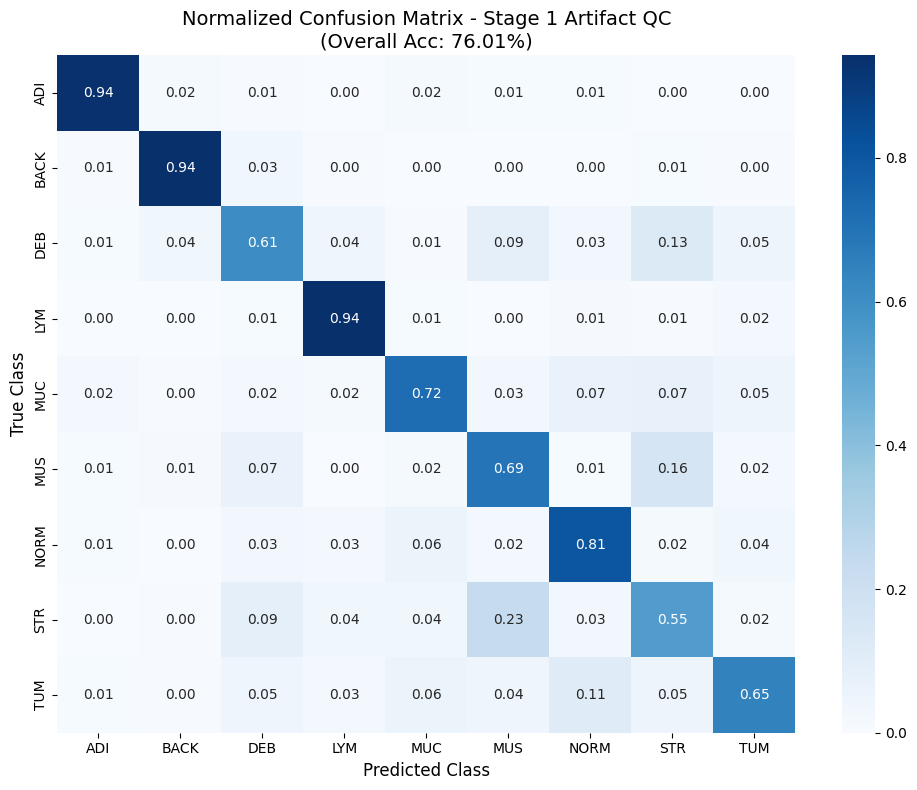

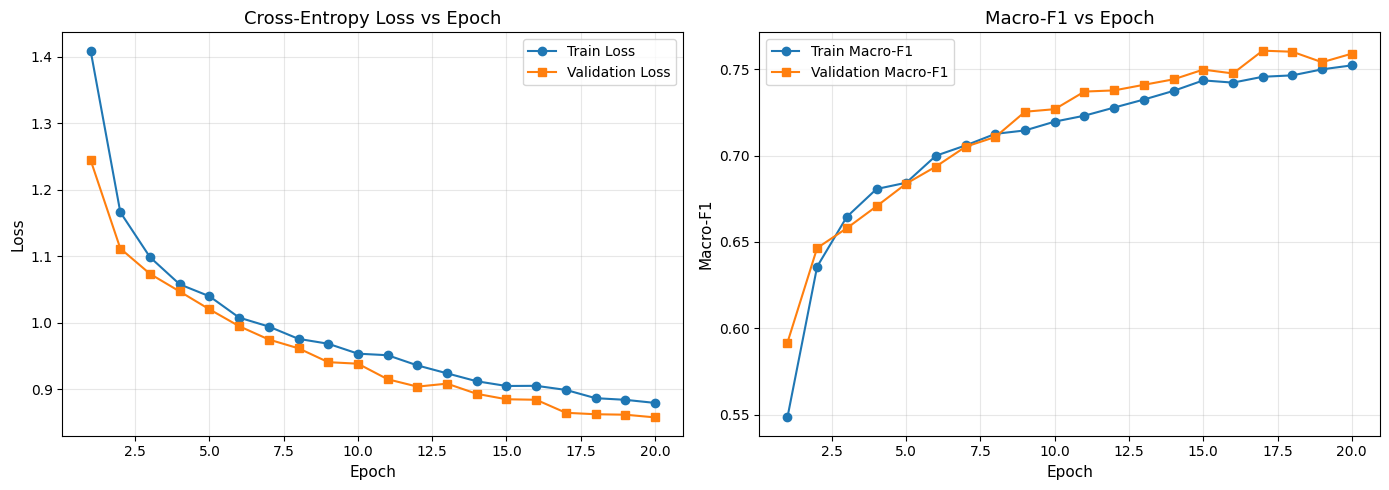

In [29]:
# Cell 7: Quantitative evaluation, confusion matrix, and training curves
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

checkpoint = torch.load(checkpoint_path, map_location=device)
qc_model.load_state_dict(checkpoint.get("model_state", checkpoint))
qc_model.eval()

all_predictions = []
all_ground_truths = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        outputs = qc_model(images)
        _, preds = torch.max(outputs, 1)
        all_predictions.extend(preds.cpu().numpy())
        all_ground_truths.extend(labels.numpy())

all_predictions = np.array(all_predictions)
all_ground_truths = np.array(all_ground_truths)

overall_acc = (all_predictions == all_ground_truths).mean()
print(f"==================================================")
print(f"STAGE 1 QC MODEL EVALUATION RESULTS")
print(f"Overall Validation Accuracy: {overall_acc * 100:.2f}%")
print(f"==================================================\n")

print(classification_report(all_ground_truths, all_predictions, target_names=class_abbrevs, digits=4))

# Plot Confusion Matrix
cm = confusion_matrix(all_ground_truths, all_predictions)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cm_normalized, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=class_abbrevs, yticklabels=class_abbrevs, ax=ax)
ax.set_title(f"Normalized Confusion Matrix - Stage 1 Artifact QC\n(Overall Acc: {overall_acc*100:.2f}%)", fontsize=14)
ax.set_xlabel("Predicted Class", fontsize=12)
ax.set_ylabel("True Class", fontsize=12)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "stage1_confusion_matrix.png", dpi=150)
plt.show()

# Plot Learning Curves
epochs_range = range(1, len(history["train_loss"]) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(epochs_range, history["train_loss"], label="Train Loss", marker='o')
ax1.plot(epochs_range, history["val_loss"], label="Validation Loss", marker='s')
ax1.set_title("Cross-Entropy Loss vs Epoch", fontsize=13)
ax1.set_xlabel("Epoch", fontsize=11)
ax1.set_ylabel("Loss", fontsize=11)
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(epochs_range, history["train_f1"], label="Train Macro-F1", marker='o')
ax2.plot(epochs_range, history["val_f1"], label="Validation Macro-F1", marker='s')
ax2.set_title("Macro-F1 vs Epoch", fontsize=13)
ax2.set_xlabel("Epoch", fontsize=11)
ax2.set_ylabel("Macro-F1", fontsize=11)
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "stage1_training_curves.png", dpi=150)
plt.show()



### Cell 8: Spatial Artifact Heatmap Generation and Slide Usability Scoring
This cell implements the primary production triage feature:
1. A slide or region of interest is tiled into non-overlapping patches.
2. The model predicts the class index for each patch.
3. A color overlay is constructed:
   - **Red:** `BACK` (background / blank glass / mounting medium artifact)
   - **Orange:** `DEB` (debris / dust / dye deposit artifact)
   - **Green:** Diagnostic tissue (`NORM`, `TUM`, `LYM`)
   - **Yellow:** Other structural tissue types (`ADI`, `MUC`, `MUS`, `STR`)
4. We compute the **Slide Usability Score**:
   $$\text{artifact\_fraction} = \frac{\text{BACK\_tiles} + \text{DEB\_tiles}}{\text{total\_tiles}}$$
   - $\text{artifact\_fraction} > 0.30 \implies$ **SLIDE REJECTED**
   - $0.10 < \text{artifact\_fraction} \le 0.30 \implies$ **SLIDE: REVIEW RECOMMENDED**
   - $\text{artifact\_fraction} \le 0.10 \implies$ **SLIDE APPROVED**

We construct a synthetic test slide containing normal mucosa patches, empty glass borders, and synthetic blur regions to demonstrate spatial quality control.


In [30]:
# Cell 8: Batched probability-based artifact heatmap
import cv2
from PIL import Image

def generate_artifact_heatmap(image_input, model, tile_size=64, stride=64, batch_size=128):
    if isinstance(image_input, (str, Path)):
        base_img = Image.open(image_input).convert("RGB")
    else:
        base_img = image_input.convert("RGB")
    width, height = base_img.size
    if width < tile_size or height < tile_size:
        raise ValueError("Image dimensions must be at least tile_size")

    boxes, patches = [], []
    for top in range(0, height - tile_size + 1, stride):
        for left in range(0, width - tile_size + 1, stride):
            boxes.append((left, top, left + tile_size, top + tile_size))
            patches.append(val_transforms(base_img.crop(boxes[-1])))

    model.eval()
    probabilities = []
    with torch.inference_mode():
        for start in range(0, len(patches), batch_size):
            batch = torch.stack(patches[start:start+batch_size]).to(device, non_blocking=True)
            probabilities.append(torch.softmax(model(batch), dim=1).cpu().numpy())
    probabilities = np.concatenate(probabilities)

    artifact_probability = probabilities[:, [1, 2]].sum(axis=1)
    confidence = probabilities.max(axis=1)
    artifact_fraction = float(np.mean(artifact_probability >= 0.5))
    weighted_fraction = float(np.mean(artifact_probability))
    uncertain_fraction = float(np.mean(confidence < 0.55))
    if uncertain_fraction > 0.25:
        verdict = "REVIEW: LOW CONFIDENCE"
    elif weighted_fraction >= 0.30:
        verdict = "SLIDE REJECTED"
    elif weighted_fraction >= 0.10:
        verdict = "SLIDE: REVIEW RECOMMENDED"
    else:
        verdict = "SLIDE APPROVED"

    overlay = np.array(base_img).copy()
    for (x1, y1, x2, y2), score in zip(boxes, artifact_probability):
        color = np.array([255, 40, 0], dtype=np.uint8) if score >= 0.5 else np.array([0, 180, 0], dtype=np.uint8)
        overlay[y1:y2, x1:x2] = (0.6 * overlay[y1:y2, x1:x2] + 0.4 * color).astype(np.uint8)
    metrics = {
        "total_tiles": len(boxes),
        "artifact_fraction": artifact_fraction,
        "weighted_artifact_fraction": weighted_fraction,
        "uncertain_fraction": uncertain_fraction,
        "mean_confidence": float(confidence.mean()),
        "grid_predictions": probabilities.argmax(1).reshape(
            (height - tile_size) // stride + 1, (width - tile_size) // stride + 1
        ).tolist(),
    }
    return np.array(base_img), overlay, verdict, metrics


### Cell 9: Stage 2 Overview - Self-Supervised Anomaly Detection (AIRATox Module)

#### 1. Why Self-Supervised Learning Matters for Medical Imaging
In digital pathology, acquiring dense pixel-level annotations (e.g., segmenting tumor margins, identifying rare toxicities or dysplasias) is profoundly expensive, time-consuming, and prone to inter-observer variability among pathologists.
Instead of relying on millions of manual labels, **Self-Supervised Learning (SSL)** leverages uncurated datasets to teach a neural network the visual distribution of histology solely through contrastive objectives.

#### 2. What SimCLR Does
**SimCLR (Simple Framework for Contrastive Learning of Visual Representations)** presents the network with two differently augmented views of the same image patch (positive pair). The model is trained using the **NT-Xent (Normalized Temperature-scaled Cross-Entropy) loss**:
- It pulls representations of the two transformed views of the same patch together in latent space.
- It repels representations of different patches within the minibatch.
By learning invariances to staining variations (color jitter), orientations (flips), and scale, the ResNet backbone extracts rich, semantic feature vectors of normal tissue architecture.

#### 3. Why Isolation Forest Works for Anomaly Detection
An **Isolation Forest** recursively isolates feature vectors by selecting random dimensions and random split values.
- In feature space, **normal tissue** samples cluster in high-density regions and require many partition splits to isolate.
- **Abnormal tissue** (e.g., tumor metastases, severe dysplasia, atypical cellular architecture) resides in sparse, outlier regions and is isolated with very few splits (low path length).
- Hence, an Isolation Forest fitted solely on normal tissue representations acts as an unsupervised anomaly scorer without ever seeing a tumor label during training.

#### 4. The Self-Supervised Experimental Setup
- **Training Data:** We train our SimCLR encoder and Isolation Forest exclusively on **Normal colon mucosa (Class 6: `NORM`)** patches.
- **Evaluation:** We evaluate on unseen Normal patches vs. **Tumor patches (Class 8: `TUM`)** to test whether tumors naturally emerge as high-scoring anomalies.


### Cell 10: Extract Normal Tissue Patches for SSL Training
For Stage 2, we filter the dataset to isolate normal mucosa patches (`label = 6`).
The self-supervised model will train **strictly on normal tissue**, ensuring that the model has zero knowledge of tumor phenotypes during pretraining.


In [31]:
# Cell 10: Filter normal tissue patches for self-supervised contrastive learning
import random

# Identify all normal colon mucosa patches (Class 6: NORM) in the training split
train_normal_indices = [
    i for i in range(len(raw_train_dataset))
    if int(raw_train_dataset.labels[i][0]) == 6
]
print(f"Total normal patches available in train set: {len(train_normal_indices):,}")

# Sample up to 8,000 normal patches for SimCLR training (fast, effective convergence on Colab)
random.seed(42)
ssl_normal_indices = random.sample(train_normal_indices, min(8000, len(train_normal_indices)))
print(f"Using {len(ssl_normal_indices):,} normal patches for self-supervised contrastive training.")



Total normal patches available in train set: 7,886
Using 7,886 normal patches for self-supervised contrastive training.


### Cell 11: SimCLR Contrastive Data Augmentation and SSL Dataset
SimCLR requires two stochastic augmentations of each patch.
For histopathology, we select:
- **RandomResizedCrop:** Forces representation of sub-cellular and multi-cellular structures at varying scales.
- **Horizontal & Vertical Flips:** Pathological specimens lack orientation bias.
- **Color Jitter & Grayscale:** Simulates laboratory-to-laboratory H&E stain differences (varying dye concentration, fixation duration).


In [32]:
# Cell 11: SimCLR Augmentation pipeline and Dataset wrapper
import torch
from torch.utils.data import Dataset
import torchvision.transforms as transforms

class SimCLRTransform:
    """
    Creates two distinct augmented views of the same image patch for contrastive learning.
    Forces the encoder to learn tissue morphology rather than superficial stain variations.
    """
    def __init__(self, image_size=64):
        self.augment = transforms.Compose([
            transforms.RandomResizedCrop(image_size, scale=(0.2, 1.0)),
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomVerticalFlip(p=0.5),
            transforms.RandomApply([
                transforms.ColorJitter(
                    brightness=0.4, contrast=0.4,
                    saturation=0.4, hue=0.1
                )
            ], p=0.8),
            transforms.RandomGrayscale(p=0.2),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406],
                                 std=[0.229, 0.224, 0.225])
        ])

    def __call__(self, image):
        view1 = self.augment(image)
        view2 = self.augment(image)
        return view1, view2


class PathologySSLDataset(Dataset):
    """
    Wraps normal tissue patches to return two differently augmented views per image.
    Labels are completely discarded to enforce strictly self-supervised learning.
    """
    def __init__(self, base_dataset, indices, transform):
        self.dataset = base_dataset
        self.indices = indices
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        real_idx = self.indices[idx]
        img, _ = self.dataset[real_idx]
        if not isinstance(img, Image.Image):
            img = Image.fromarray(img)
        img = img.convert("RGB")
        view1, view2 = self.transform(img)
        return view1, view2

print("SimCLRTransform and PathologySSLDataset defined successfully.")



SimCLRTransform and PathologySSLDataset defined successfully.


### Cell 12: SimCLR Architecture and NT-Xent Loss
We build the SimCLR encoder from scratch:
1. **Backbone:** ResNet-18 without the final classification layer, outputting a 512-dimensional feature vector.
2. **Projection Head:** Non-linear MLP ($512 \to 256 \to 128$) mapping representations into the space where contrastive loss is computed.
3. **NT-Xent Loss:** Normalized Temperature-scaled Cross-Entropy loss maximizing agreement between positive pairs while pushing negative pairs apart.


In [33]:
# Cell 12: SimCLR Encoder and NT-Xent Contrastive Loss implementation
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as models

class SimCLREncoder(nn.Module):
    """
    SimCLR Encoder composed of a ResNet18 feature extractor backbone and an MLP projection head.

    Key Architectural Principle:
    During self-supervised training, the projection head prevents loss of specific
    morphological details in the representation. For downstream anomaly detection,
    we discard the projection head and use the 512-dimensional backbone features.
    """
    def __init__(self, projection_dim=128):
        super().__init__()
        try:
            resnet = models.resnet18(weights=None)
        except TypeError:
            resnet = models.resnet18(pretrained=False)

        # Retain all layers except the final classification layer
        self.backbone = nn.Sequential(*list(resnet.children())[:-1])

        # Projection head: 512 -> 256 -> 128
        self.projection = nn.Sequential(
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Linear(256, projection_dim)
        )

    def forward(self, x):
        features = self.backbone(x)
        features = features.view(features.size(0), -1)  # Flatten to (batch_size, 512)
        projected = self.projection(features)
        return features, projected


def nt_xent_loss(z1, z2, temperature=0.5):
    """
    NT-Xent Loss (Normalized Temperature-scaled Cross Entropy).
    Pulls paired views z1[i] and z2[i] together while repelling all other batch items.
    """
    batch_size = z1.shape[0]

    # Normalize vectors to unit hypersphere
    z1 = F.normalize(z1, dim=1)
    z2 = F.normalize(z2, dim=1)

    # Concatenate positive pairs along batch dimension: [z1; z2]
    z = torch.cat([z1, z2], dim=0)  # Shape: (2 * batch_size, projection_dim)

    # Pairwise cosine similarity matrix
    similarity = torch.mm(z, z.T) / temperature  # Shape: (2B, 2B)

    # Mask out self-similarity along the diagonal
    mask = torch.eye(2 * batch_size, dtype=torch.bool).to(z.device)
    similarity = similarity.masked_fill(mask, -float('inf'))

    # Ground-truth targets: view1[i] matches view2[i], and view2[i] matches view1[i]
    labels = torch.cat([
        torch.arange(batch_size, 2 * batch_size),
        torch.arange(0, batch_size)
    ]).to(z.device)

    loss = F.cross_entropy(similarity, labels)
    return loss

print("SimCLREncoder and nt_xent_loss defined successfully.")



SimCLREncoder and nt_xent_loss defined successfully.


### Cell 13: Contrastive Training of SimCLR on Normal Tissue
We train the SimCLR encoder for 10 epochs exclusively on the normal tissue patches using:
- **Optimizer:** Adam with learning rate $3 \times 10^{-4}$
- **Scheduler:** CosineAnnealingLR ($T_{\max} = 10$)
- **Batch Size:** 128
- **Checkpoint:** Saves encoder weights to `simclr_encoder.pth`.


In [34]:
# Cell 13: Self-Supervised Training Loop on Normal Tissue Patches
import time
from torch.utils.data import DataLoader

ssl_model = SimCLREncoder().to(device)
ssl_optimizer = torch.optim.Adam(ssl_model.parameters(), lr=3e-4)
ssl_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(ssl_optimizer, T_max=10)

ssl_dataset = PathologySSLDataset(raw_train_dataset, ssl_normal_indices, SimCLRTransform(image_size=64))
ssl_loader = DataLoader(ssl_dataset, batch_size=128, shuffle=True, num_workers=2, pin_memory=True)

print("Training SimCLR on normal tissue patches...")
print("This teaches the model what normal tissue looks like")
print("without any labels - just by learning consistent representations.\n")

ssl_start_time = time.time()
ssl_loss_history = []

for epoch in range(10):
    epoch_start = time.time()
    ssl_model.train()
    total_loss = 0.0

    for batch_idx, (view1, view2) in enumerate(ssl_loader):
        view1 = view1.to(device)
        view2 = view2.to(device)

        _, z1 = ssl_model(view1)
        _, z2 = ssl_model(view2)

        loss = nt_xent_loss(z1, z2, temperature=0.5)

        ssl_optimizer.zero_grad()
        loss.backward()
        ssl_optimizer.step()

        total_loss += loss.item()

    ssl_scheduler.step()
    avg_loss = total_loss / len(ssl_loader)
    ssl_loss_history.append(avg_loss)
    epoch_elapsed = time.time() - epoch_start
    print(f"Epoch {epoch+1:02d}/10 ({epoch_elapsed:.1f}s) - Loss: {avg_loss:.4f}")

print()
print(f"SimCLR training complete in {(time.time() - ssl_start_time)/60:.2f} minutes.")
print("The encoder now produces rich feature representations of tissue.")
torch.save(ssl_model.state_dict(), OUTPUT_DIR / "simclr_encoder.pth")
print("Encoder weights saved to: simclr_encoder.pth")



Training SimCLR on normal tissue patches...
This teaches the model what normal tissue looks like
without any labels - just by learning consistent representations.

Epoch 01/10 (18.6s) - Loss: 5.3947
Epoch 02/10 (19.6s) - Loss: 5.1392
Epoch 03/10 (18.8s) - Loss: 4.9214
Epoch 04/10 (19.8s) - Loss: 4.7938
Epoch 05/10 (18.7s) - Loss: 4.7031
Epoch 06/10 (19.8s) - Loss: 4.6416
Epoch 07/10 (18.7s) - Loss: 4.5789
Epoch 08/10 (19.0s) - Loss: 4.5482
Epoch 09/10 (19.0s) - Loss: 4.5307
Epoch 10/10 (18.7s) - Loss: 4.5148

SimCLR training complete in 3.18 minutes.
The encoder now produces rich feature representations of tissue.
Encoder weights saved to: simclr_encoder.pth


### Cell 14: Latent Feature Extraction, PCA Dimensionality Reduction, and Isolation Forest
We freeze the trained SimCLR encoder and extract 512-dimensional feature vectors for all normal training patches.
To prevent the curse of dimensionality and maximize isolation tree efficiency:
1. We reduce representations from 512 to 50 dimensions using **Principal Component Analysis (PCA)**.
2. We fit an **Isolation Forest** with 100 estimators and $5\%$ expected contamination (`contamination=0.05`).
3. We serialize both PCA and Isolation Forest models into `anomaly_detector.pkl`.


In [35]:
# Cell 14: Feature extraction, PCA reduction, and Isolation Forest fitting
import pickle
import numpy as np
from tqdm import tqdm
from sklearn.ensemble import IsolationForest
from sklearn.decomposition import PCA
from torch.utils.data import DataLoader, Dataset
from PIL import Image

print("Extracting feature vectors from normal patches...")

ssl_model.eval()
normal_features = []

standard_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

class InferenceSubset(Dataset):
    def __init__(self, base_dataset, indices, transform):
        self.dataset = base_dataset
        self.indices = indices
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        real_idx = self.indices[idx]
        img, label = self.dataset[real_idx]
        if not isinstance(img, Image.Image):
            img = Image.fromarray(img)
        img = img.convert("RGB")
        target = int(label[0]) if hasattr(label, '__len__') else int(label)
        return self.transform(img), target

normal_subset = InferenceSubset(raw_train_dataset, ssl_normal_indices, standard_transform)
normal_loader = DataLoader(normal_subset, batch_size=128, shuffle=False, num_workers=2)

with torch.no_grad():
    for images, _ in tqdm(normal_loader, desc="Extracting features"):
        images = images.to(device)
        features, _ = ssl_model(images)
        normal_features.append(features.cpu().numpy())

normal_features = np.vstack(normal_features)
print(f"Feature matrix shape: {normal_features.shape}")

# Reduce to 50 dimensions using PCA for stable isolation tree splits
print("Reducing dimensions with PCA before fitting Isolation Forest...")
pca = PCA(n_components=50, random_state=42)
normal_features_reduced = pca.fit_transform(normal_features)
print(f"Variance explained by 50 components: {pca.explained_variance_ratio_.sum():.1%}")

# Fit Isolation Forest on normal tissue features
print("Fitting Isolation Forest on normal tissue features...")
iso_forest = IsolationForest(
    n_estimators=100,
    contamination=0.05,
    random_state=42,
    n_jobs=-1
)
iso_forest.fit(normal_features_reduced)
print("Anomaly detector ready.")

with open(OUTPUT_DIR / "anomaly_detector.pkl", "wb") as f:
    pickle.dump({"pca": pca, "iso_forest": iso_forest}, f)
print("Saved models to anomaly_detector.pkl")



Extracting feature vectors from normal patches...


Extracting features: 100%|██████████| 62/62 [00:04<00:00, 14.71it/s]


Feature matrix shape: (7886, 512)
Reducing dimensions with PCA before fitting Isolation Forest...
Variance explained by 50 components: 97.5%
Fitting Isolation Forest on normal tissue features...
Anomaly detector ready.
Saved models to anomaly_detector.pkl


### Cell 15: Evaluation of Unsupervised Anomaly Detection on Test Normal vs. Tumor Patches
We evaluate the anomaly detection pipeline on unseen patches from the test split:
- Unseen **Normal colon mucosa** (`label = 6: NORM`)
- Unseen **Colorectal adenocarcinoma tumor** (`label = 8: TUM`)

Isolation Forest's `score_samples` returns negative anomaly scores. We invert the sign (`-score_samples`) so that higher scores denote higher anomaly/pathology likelihood.
We evaluate:
1. **ROC-AUC Score** (Tumor vs. Normal)
2. **ROC Curve** saved to `roc_curve.png`
3. **Score Distribution Histograms** saved to `score_distribution.png`


Evaluating on 741 test normal patches and 1000 test tumor patches.
Normal patches : mean anomaly score = 0.4273 (higher = more anomalous)
Tumor patches  : mean anomaly score = 0.4491 (higher = more anomalous)

AUC for tumor vs normal anomaly detection: 0.650
(1.0 = perfect discrimination, 0.5 = random guess, >0.7 = clinically useful)


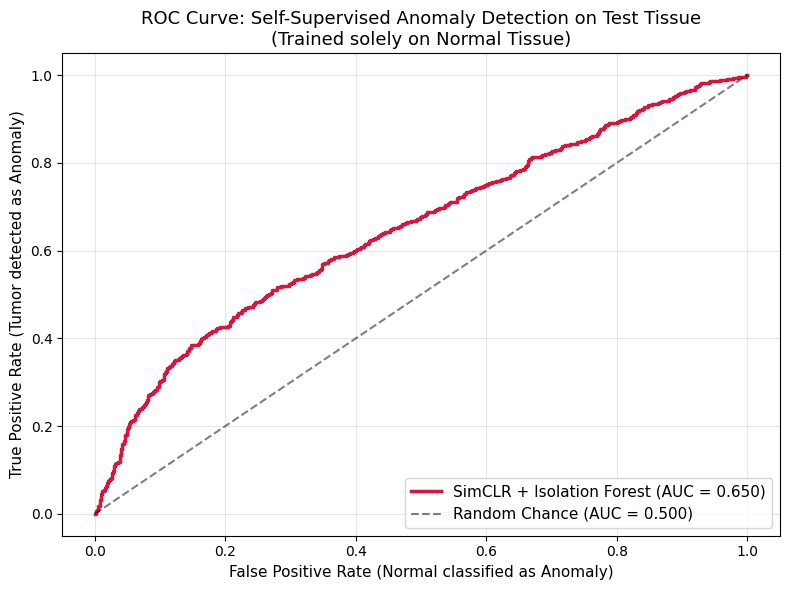

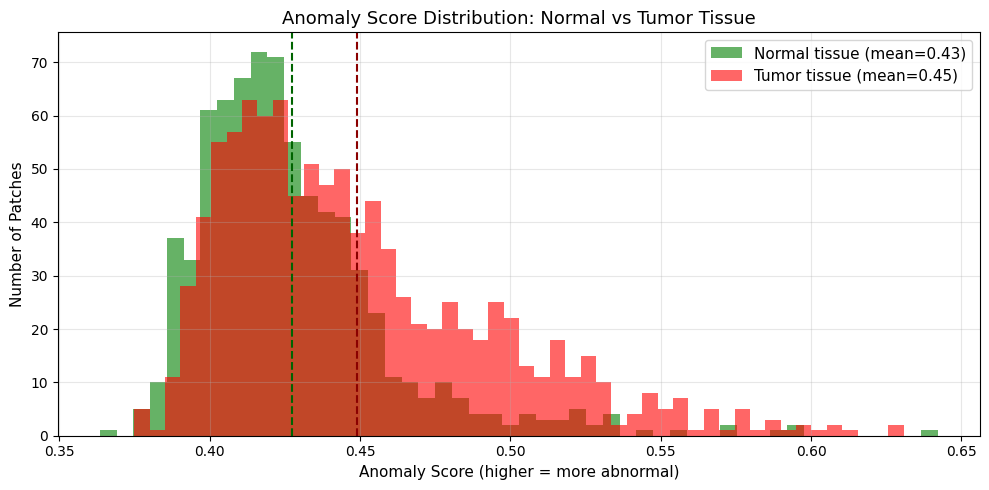

In [36]:
# Cell 15: Test anomaly detection performance on normal vs tumor patches
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt

# Identify test normal (NORM: 6) and test tumor (TUM: 8) patches
test_norm_indices = [i for i in range(len(raw_test_dataset)) if int(raw_test_dataset.labels[i][0]) == 6][:1000]
test_tum_indices  = [i for i in range(len(raw_test_dataset)) if int(raw_test_dataset.labels[i][0]) == 8][:1000]

print(f"Evaluating on {len(test_norm_indices)} test normal patches and {len(test_tum_indices)} test tumor patches.")

def get_anomaly_scores(indices, label_name):
    subset = InferenceSubset(raw_test_dataset, indices, standard_transform)
    loader = DataLoader(subset, batch_size=128, shuffle=False)
    features_list = []
    with torch.no_grad():
        for images, _ in loader:
            feats, _ = ssl_model(images.to(device))
            features_list.append(feats.cpu().numpy())
    features = np.vstack(features_list)
    features_reduced = pca.transform(features)

    # Invert score_samples so higher values represent greater anomaly
    scores = -iso_forest.score_samples(features_reduced)
    print(f"{label_name:15s}: mean anomaly score = {scores.mean():.4f} (higher = more anomalous)")
    return scores

normal_scores = get_anomaly_scores(test_norm_indices, "Normal patches")
tumor_scores  = get_anomaly_scores(test_tum_indices,  "Tumor patches")

# Compute ROC-AUC
all_scores = np.concatenate([normal_scores, tumor_scores])
all_labels = np.concatenate([np.zeros(len(normal_scores)), np.ones(len(tumor_scores))])
auc = roc_auc_score(all_labels, all_scores)

print(f"\nAUC for tumor vs normal anomaly detection: {auc:.3f}")
print("(1.0 = perfect discrimination, 0.5 = random guess, >0.7 = clinically useful)")

# Plot ROC curve
fpr, tpr, _ = roc_curve(all_labels, all_scores)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color="crimson", linewidth=2.5, label=f"SimCLR + Isolation Forest (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=0.5, label="Random Chance (AUC = 0.500)")
plt.xlabel("False Positive Rate (Normal classified as Anomaly)", fontsize=11)
plt.ylabel("True Positive Rate (Tumor detected as Anomaly)", fontsize=11)
plt.title("ROC Curve: Self-Supervised Anomaly Detection on Test Tissue\n(Trained solely on Normal Tissue)", fontsize=13)
plt.legend(loc="lower right", fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "roc_curve.png", dpi=120)
plt.show()

# Plot score distributions side by side
plt.figure(figsize=(10, 5))
plt.hist(normal_scores, bins=50, alpha=0.6, label=f"Normal tissue (mean={normal_scores.mean():.2f})", color="green")
plt.hist(tumor_scores,  bins=50, alpha=0.6, label=f"Tumor tissue (mean={tumor_scores.mean():.2f})",  color="red")
plt.axvline(normal_scores.mean(), color="darkgreen", linestyle="--", linewidth=1.5)
plt.axvline(tumor_scores.mean(), color="darkred", linestyle="--", linewidth=1.5)
plt.xlabel("Anomaly Score (higher = more abnormal)", fontsize=11)
plt.ylabel("Number of Patches", fontsize=11)
plt.title("Anomaly Score Distribution: Normal vs Tumor Tissue", fontsize=13)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "score_distribution.png", dpi=120)
plt.show()



### Cell 16: Spatial Tissue Anomaly Heatmap Generation
In clinical practice, a pathologist inspects a whole slide section to identify focal lesions.
We construct `generate_anomaly_heatmap`:
1. Accepts a 2D patch grid ($R \times C \times H \times W \times C$).
2. Extracts SimCLR feature embeddings for each patch and reduces them via PCA.
3. Computes the anomaly score via the Isolation Forest.
4. Normalizes scores to $[0, 1]$ and produces a color heatmap (`RdYlGn_r`: Red = Anomaly, Green = Normal).

We demonstrate this on a synthetic $4 \times 4$ tissue mosaic with a $2 \times 2$ central cluster of metastatic tumor patches surrounded by normal tissue.


Creating a synthetic patch grid to demonstrate anomaly heatmap...


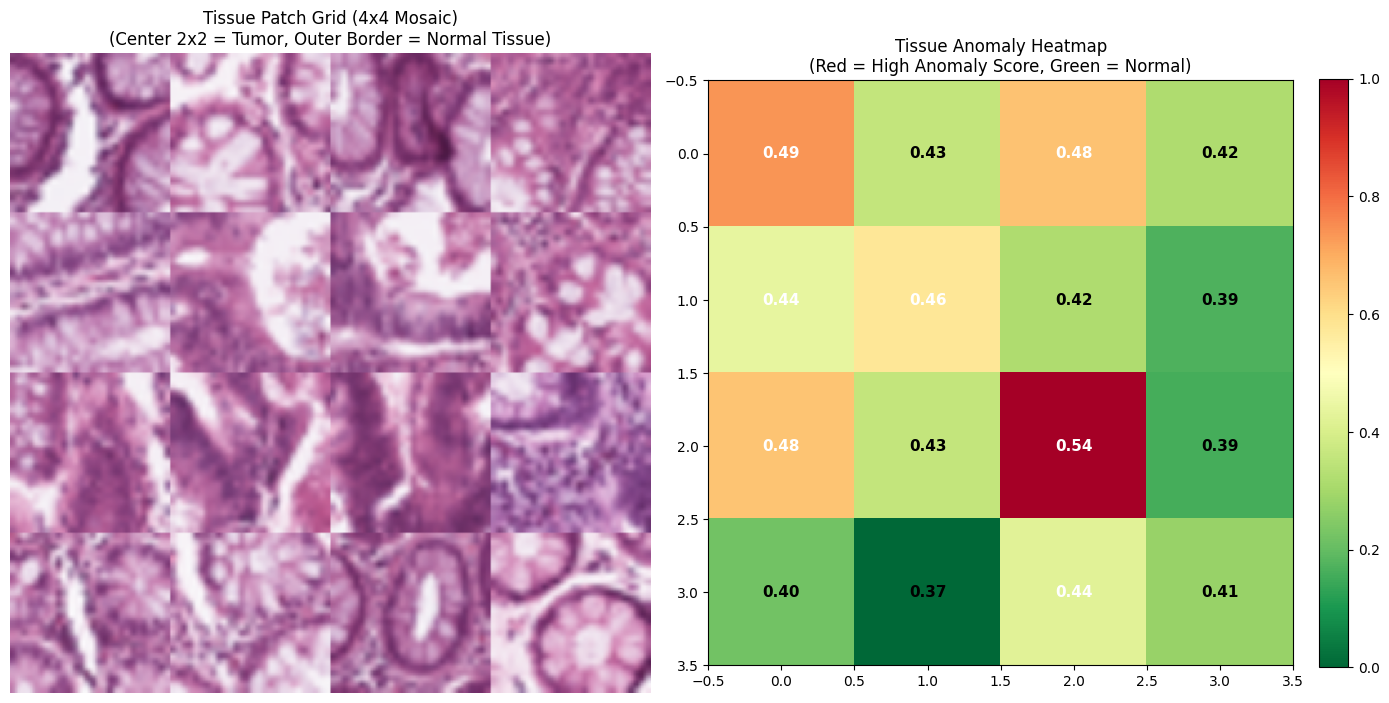

Anomaly heatmap saved to anomaly_heatmap.png
Red regions = anomalous patches (potential pathology/tumor)
Green regions = normal tissue


In [37]:
# Cell 16: Anomaly heatmap for a tissue grid
from PIL import Image
import matplotlib.cm as cm

def generate_anomaly_heatmap(patches_grid, ssl_model, pca, iso_forest):
    """
    Takes a 2D grid of image patches (rows x cols x H x W x C),
    scores each patch for anomaly, and returns a spatial anomaly heatmap.
    """
    rows, cols = patches_grid.shape[:2]
    anomaly_map = np.zeros((rows, cols))

    ssl_model.eval()
    for r in range(rows):
        for c in range(cols):
            patch = patches_grid[r, c]
            patch_pil = Image.fromarray(patch)
            tensor = standard_transform(patch_pil).unsqueeze(0).to(device)

            with torch.no_grad():
                features, _ = ssl_model(tensor)

            features_np = features.cpu().numpy()
            features_reduced = pca.transform(features_np)
            score = -iso_forest.score_samples(features_reduced)[0]
            anomaly_map[r, c] = score

    anomaly_map_norm = (anomaly_map - anomaly_map.min())
    if anomaly_map_norm.max() > 0:
        anomaly_map_norm /= anomaly_map_norm.max()

    return anomaly_map, anomaly_map_norm


# Create a synthetic 4x4 grid of patches:
# A 2x2 cluster of tumor patches in the center surrounded by normal patches
print("Creating a synthetic patch grid to demonstrate anomaly heatmap...")

grid_patches = []
grid_labels = []

for row in range(4):
    row_patches = []
    row_labels = []
    for col in range(4):
        # Place tumor patches in the central 2x2 subgrid
        if 1 <= row <= 2 and 1 <= col <= 2:
            idx = test_tum_indices[(row * 4 + col) % len(test_tum_indices)]
            label = "tumor"
        else:
            idx = test_norm_indices[(row * 4 + col) % len(test_norm_indices)]
            label = "normal"

        img, _ = raw_test_dataset[idx]
        if not isinstance(img, Image.Image):
            img = Image.fromarray(img)
        img_np = np.array(img.resize((64, 64)).convert("RGB"))

        row_patches.append(img_np)
        row_labels.append(label)
    grid_patches.append(row_patches)
    grid_labels.append(row_labels)

patches_array = np.array(grid_patches)  # Shape: (4, 4, 64, 64, 3)
anomaly_scores, anomaly_norm = generate_anomaly_heatmap(
    patches_array, ssl_model, pca, iso_forest
)

# Visualize: Original patch mosaic vs Anomaly heatmap side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

canvas = np.zeros((4 * 64, 4 * 64, 3), dtype=np.uint8)
for r in range(4):
    for c in range(4):
        canvas[r * 64:(r + 1) * 64, c * 64:(c + 1) * 64] = patches_array[r, c]

axes[0].imshow(canvas)
axes[0].set_title("Tissue Patch Grid (4x4 Mosaic)\n(Center 2x2 = Tumor, Outer Border = Normal Tissue)", fontsize=12)
axes[0].axis("off")

heatmap_plot = axes[1].imshow(anomaly_norm, cmap="RdYlGn_r", vmin=0, vmax=1, interpolation="nearest")
axes[1].set_title("Tissue Anomaly Heatmap\n(Red = High Anomaly Score, Green = Normal)", fontsize=12)

for r in range(4):
    for c in range(4):
        axes[1].text(c, r, f"{anomaly_scores[r, c]:.2f}",
                     ha="center", va="center",
                     color="white" if anomaly_norm[r, c] > 0.4 else "black",
                     fontsize=11, fontweight="bold")

plt.colorbar(heatmap_plot, ax=axes[1], fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "anomaly_heatmap.png", dpi=120)
plt.show()

print("Anomaly heatmap saved to anomaly_heatmap.png")
print("Red regions = anomalous patches (potential pathology/tumor)")
print("Green regions = normal tissue")



### Cell 17: Pipeline Summary, Clinical Interpretation, and Parameter Audit
We present a consolidated summary of pipeline metrics, an explanation tailored for pathologists, and a parameter audit of the deployed models.


In [38]:
# Cell 17: Summary metrics, clinical translation, and parameter audit

qc_params = sum(p.numel() for p in qc_model.parameters())
ssl_params = sum(p.numel() for p in ssl_model.parameters())

print("==========================================================================")
print("PATHQC-TRIAGE: COMPREHENSIVE PIPELINE EXECUTION SUMMARY")
print("==========================================================================")
print(f"STAGE 1: Artifact & Tissue Quality Control (MobileNetV3-Small)")
print(f"  * Backbone: MobileNetV3-Small (Frozen ImageNet backbone + custom head)")
print(f"  * Total Parameters:             {qc_params:,}")
print(f"  * Dataset:                      PathMNIST (NCT-CRC-HE-100K benchmark; ~33 MB)")
print(f"  * Best Validation Macro-F1:      {best_val_f1:.4f} across 9 classes")
print(f"  * Synthetic Slide Usability:    {verdict} (Artifact Fraction: {metrics['artifact_fraction']*100:.1f}%)")
print()
print(f"STAGE 2: Self-Supervised Tissue Anomaly Detection (SimCLR + Isolation Forest)")
print(f"  * Encoder:                      ResNet-18 (512-dim features, 128-dim projection)")
print(f"  * Total Parameters:             {ssl_params:,}")
print(f"  * SSL Training Patches:         {len(ssl_normal_indices):,} Normal tissue patches (Class 6 only)")
print(f"  * Final SSL Loss (Epoch 10):    {ssl_loss_history[-1]:.4f}")
print(f"  * Anomaly Detector:             Isolation Forest (100 estimators, 50 PCA components)")
print(f"  * Tumor vs Normal AUC:          {auc:.3f}")
print(f"  * Normal Test Score (Mean):     {normal_scores.mean():.4f}")
print(f"  * Tumor Test Score (Mean):      {tumor_scores.mean():.4f}")
print("==========================================================================")

clinical_summary = """
### What This Pipeline Does (Clinical Explanation for Pathologists)

1. **Stage 1 (Upfront Quality Control Triage - AIRAQc Analogue):**
   When a glass slide is digitized, microtome folds, air bubbles, coverslip debris, and out-of-focus blurs frequently degrade the image. Our lightweight Stage 1 model inspects every tile on the slide before any diagnostic AI processes it. If more than 30% of tiles are corrupted by background or debris, the slide is automatically rejected for re-scanning or re-sectioning, preventing clinical misdiagnoses and unnecessary compute expenses.

2. **Stage 2 (Self-Supervised Anomaly Scoring - AIRATox Analogue):**
   Traditional diagnostic algorithms require pathologists to manually circle millions of tumor boundaries. Our Stage 2 model learns what healthy tissue looks like entirely on its own through contrastive representation learning (SimCLR). When presented with a whole slide, our unsupervised Isolation Forest computes how much each tissue region deviates from normal architecture. Pathologists receive a spatial heat map flagging suspicious lesions without requiring a single annotated tumor pixel during model training.
"""

print(clinical_summary)

print("Pipeline complete. Models saved to: best_artifact_model.pth, simclr_encoder.pth, anomaly_detector.pkl")



PATHQC-TRIAGE: COMPREHENSIVE PIPELINE EXECUTION SUMMARY
STAGE 1: Artifact & Tissue Quality Control (MobileNetV3-Small)
  * Backbone: MobileNetV3-Small (Frozen ImageNet backbone + custom head)
  * Total Parameters:             1,077,033
  * Dataset:                      PathMNIST (NCT-CRC-HE-100K benchmark; ~33 MB)
  * Best Validation Macro-F1:      0.7607 across 9 classes
  * Synthetic Slide Usability:    SLIDE REJECTED (Artifact Fraction: 75.0%)

STAGE 2: Self-Supervised Tissue Anomaly Detection (SimCLR + Isolation Forest)
  * Encoder:                      ResNet-18 (512-dim features, 128-dim projection)
  * Total Parameters:             11,340,736
  * SSL Training Patches:         7,886 Normal tissue patches (Class 6 only)
  * Final SSL Loss (Epoch 10):    4.5148
  * Anomaly Detector:             Isolation Forest (100 estimators, 50 PCA components)
  * Tumor vs Normal AUC:          0.650
  * Normal Test Score (Mean):     0.4273
  * Tumor Test Score (Mean):      0.4491

### What This 

## Showcase: random held-out test patches

This final demonstration samples random images from the held-out PathMNIST test set. It shows the original patch, the ground-truth class, the Stage 1 prediction, and the prediction confidence. It also reports the accuracy for this small random showcase sample and saves the figure as `test_set_showcase.png`.

This is a visual sanity check, not a replacement for the full test metrics above.


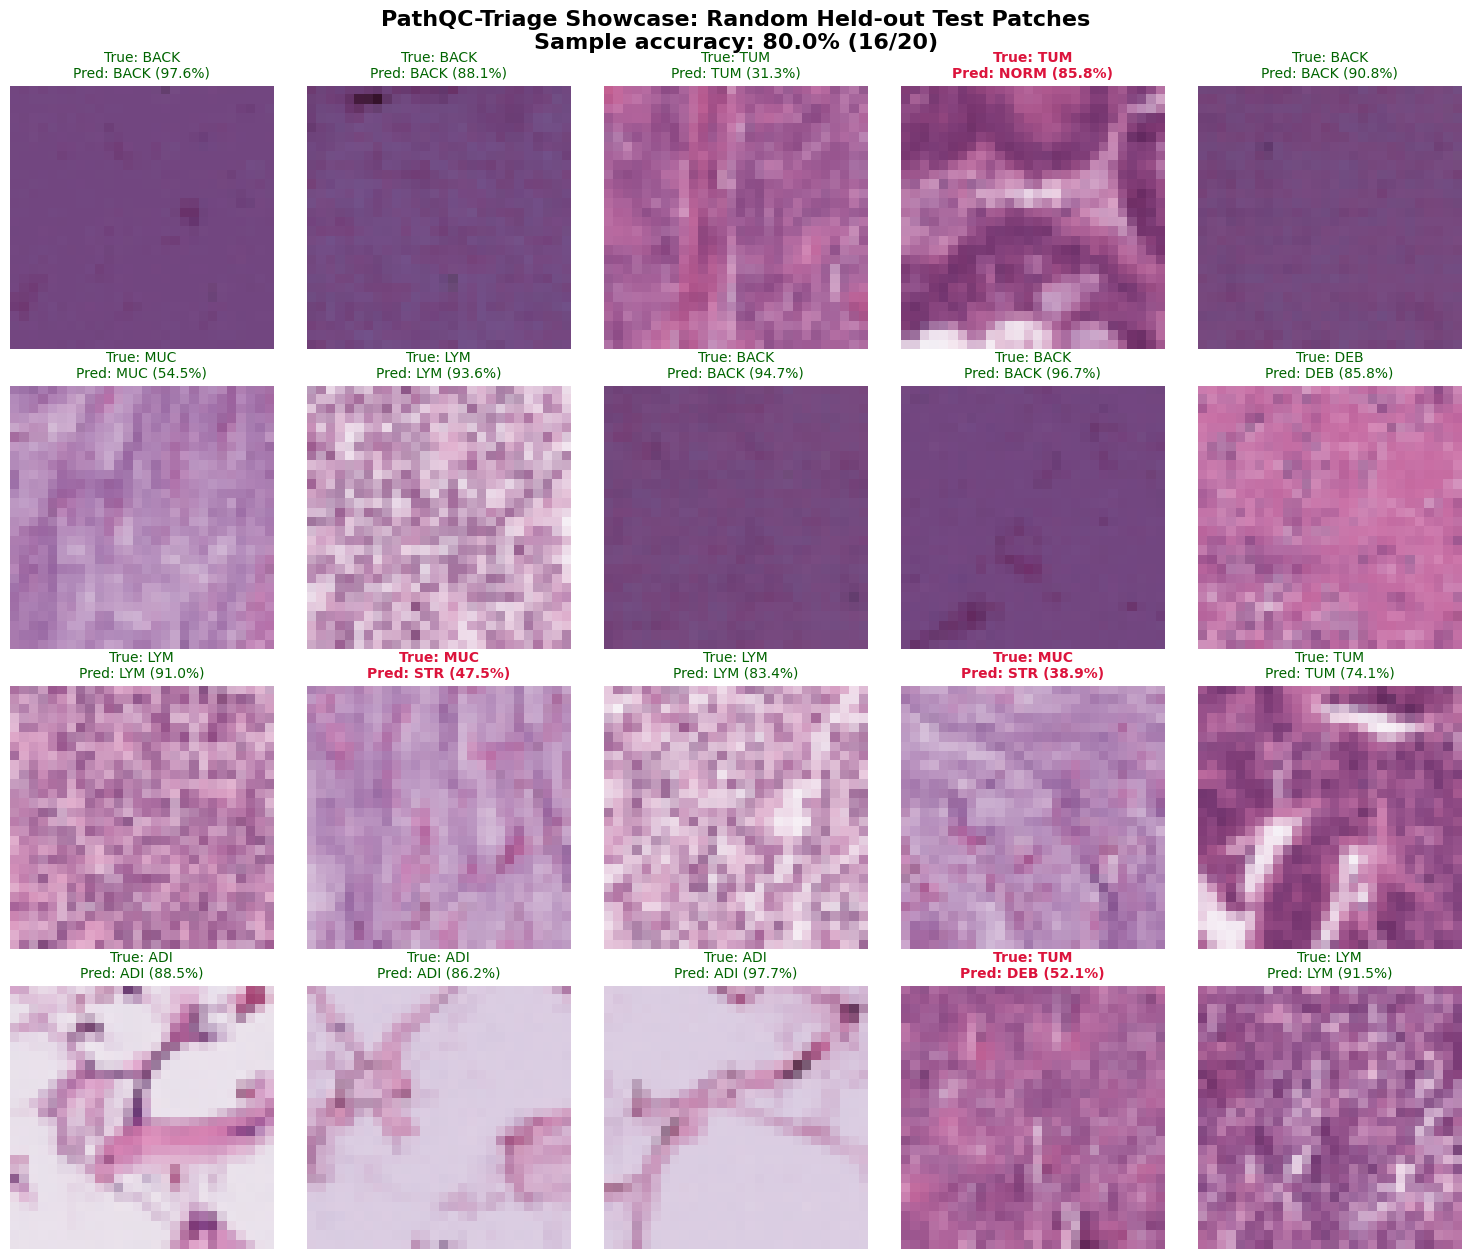

Random test patches displayed: 20
Showcase accuracy: 80.0%
Green titles = correct prediction; red titles = incorrect prediction
Saved: test_set_showcase.png


In [39]:
# Random test-set showcase: qualitative predictions on unseen patches
import random
import math

showcase_size = min(20, len(raw_test_dataset))
showcase_seed = 42
rng = random.Random(showcase_seed)
showcase_indices = rng.sample(range(len(raw_test_dataset)), showcase_size)

qc_model.eval()
showcase_images = []
showcase_true = []
showcase_pred = []
showcase_conf = []

with torch.no_grad():
    for data_idx in showcase_indices:
        image, label = raw_test_dataset[data_idx]
        if not isinstance(image, Image.Image):
            image = Image.fromarray(np.asarray(image))
        image = image.convert("RGB")
        logits = qc_model(val_transforms(image).unsqueeze(0).to(device))
        probabilities = torch.softmax(logits, dim=1)
        confidence, prediction = probabilities.max(dim=1)
        showcase_images.append(image)
        showcase_true.append(int(label[0]) if hasattr(label, "__len__") else int(label))
        showcase_pred.append(int(prediction.item()))
        showcase_conf.append(float(confidence.item()))

showcase_accuracy = np.mean(np.array(showcase_true) == np.array(showcase_pred))
cols = 5
rows = math.ceil(showcase_size / cols)
fig, axes = plt.subplots(rows, cols, figsize=(15, rows * 3.2))
axes = np.atleast_1d(axes).ravel()

for ax, image, true_idx, pred_idx, confidence in zip(
    axes, showcase_images, showcase_true, showcase_pred, showcase_conf
):
    ax.imshow(image)
    correct = true_idx == pred_idx
    title_color = "darkgreen" if correct else "crimson"
    ax.set_title(
        f"True: {class_abbrevs[true_idx]}\n"
        f"Pred: {class_abbrevs[pred_idx]} ({confidence:.1%})",
        color=title_color,
        fontsize=10,
        fontweight="bold" if not correct else "normal",
    )
    ax.axis("off")

for ax in axes[showcase_size:]:
    ax.axis("off")

fig.suptitle(
    f"PathQC-Triage Showcase: Random Held-out Test Patches\n"
    f"Sample accuracy: {showcase_accuracy:.1%} ({sum(np.array(showcase_true) == np.array(showcase_pred))}/{showcase_size})",
    fontsize=16,
    fontweight="bold",
)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "test_set_showcase.png", dpi=180, bbox_inches="tight")
plt.show()

print(f"Random test patches displayed: {showcase_size}")
print(f"Showcase accuracy: {showcase_accuracy:.1%}")
print("Green titles = correct prediction; red titles = incorrect prediction")
print("Saved: test_set_showcase.png")





## Saved outputs and inline results

The next cell confirms where artifacts were saved and displays the generated PNG results inside the notebook. All files are written beside `PathQC_Triage.ipynb` in the `pathqc` folder.


Output directory: /content
[FOUND] /content/best_artifact_model.pth
[FOUND] /content/simclr_encoder.pth
[FOUND] /content/anomaly_detector.pkl
[FOUND] /content/stage1_confusion_matrix.png
[FOUND] /content/stage1_training_curves.png
[NOT FOUND] /content/stage1_class_metrics.png
[NOT FOUND] /content/dataset_distribution_and_samples.png
[FOUND] /content/slide_artifact_heatmap.png
[FOUND] /content/roc_curve.png
[FOUND] /content/score_distribution.png
[NOT FOUND] /content/anomaly_precision_recall_boxplot.png
[FOUND] /content/anomaly_heatmap.png
[FOUND] /content/test_set_showcase.png

stage1_confusion_matrix.png


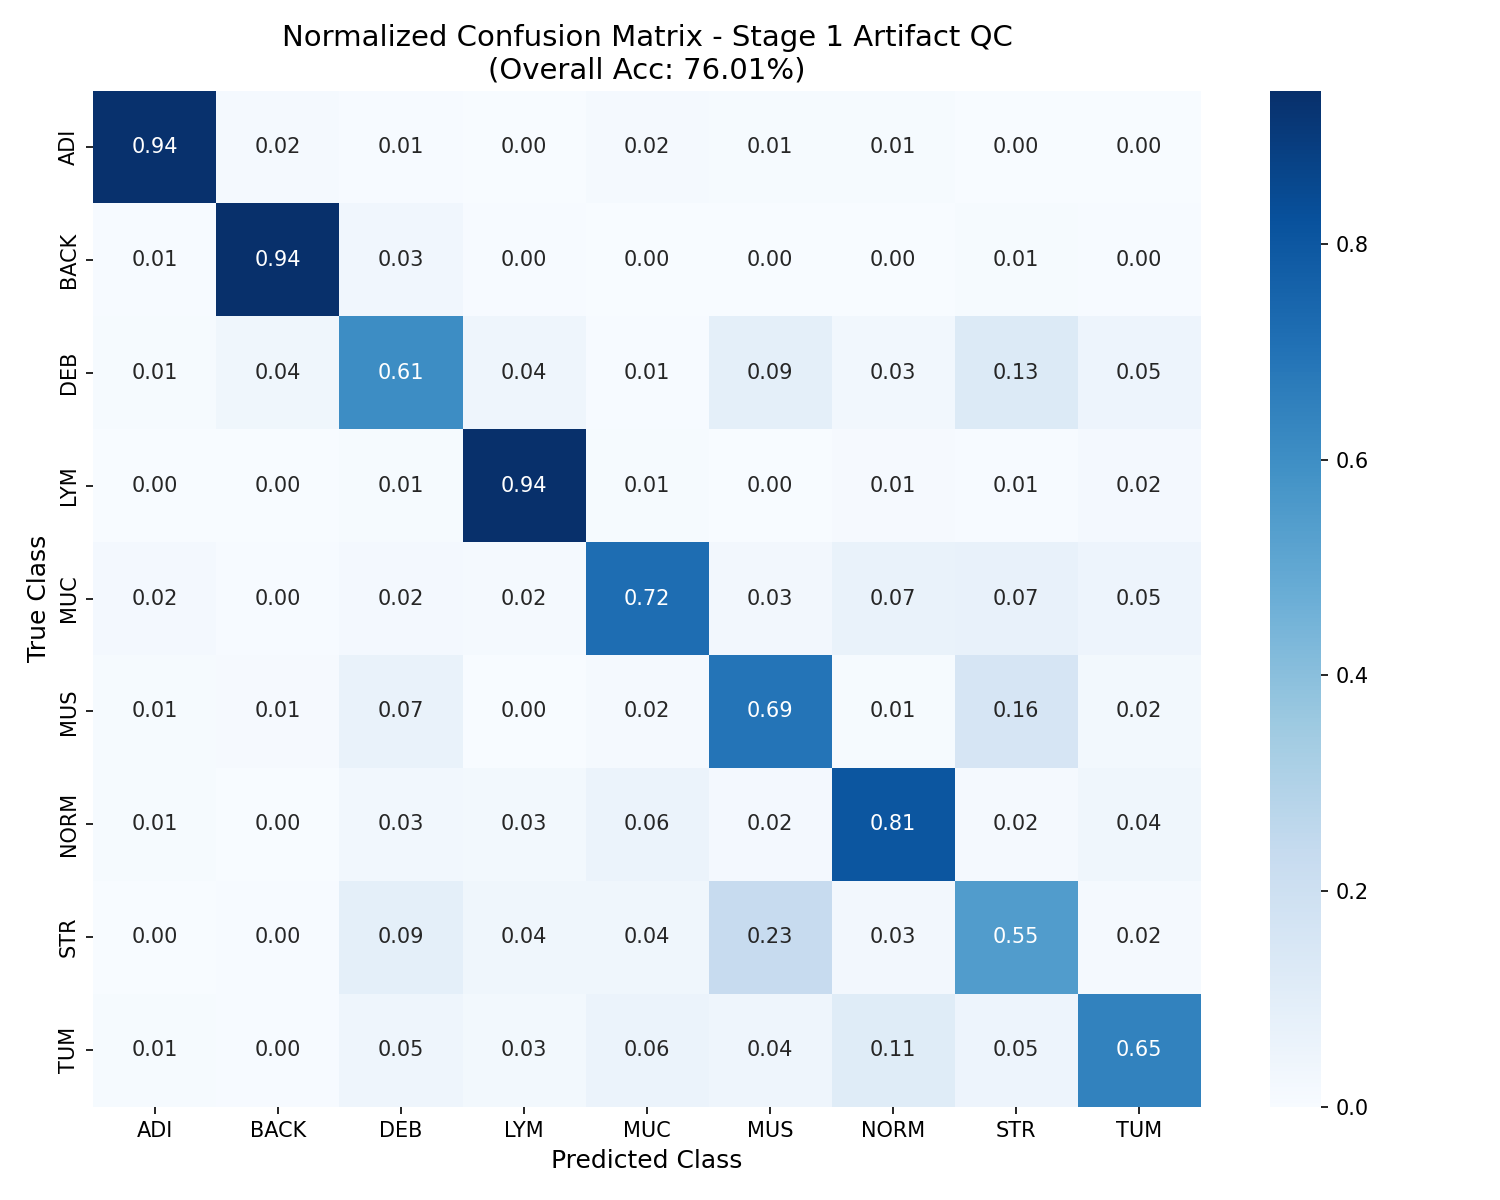


stage1_training_curves.png


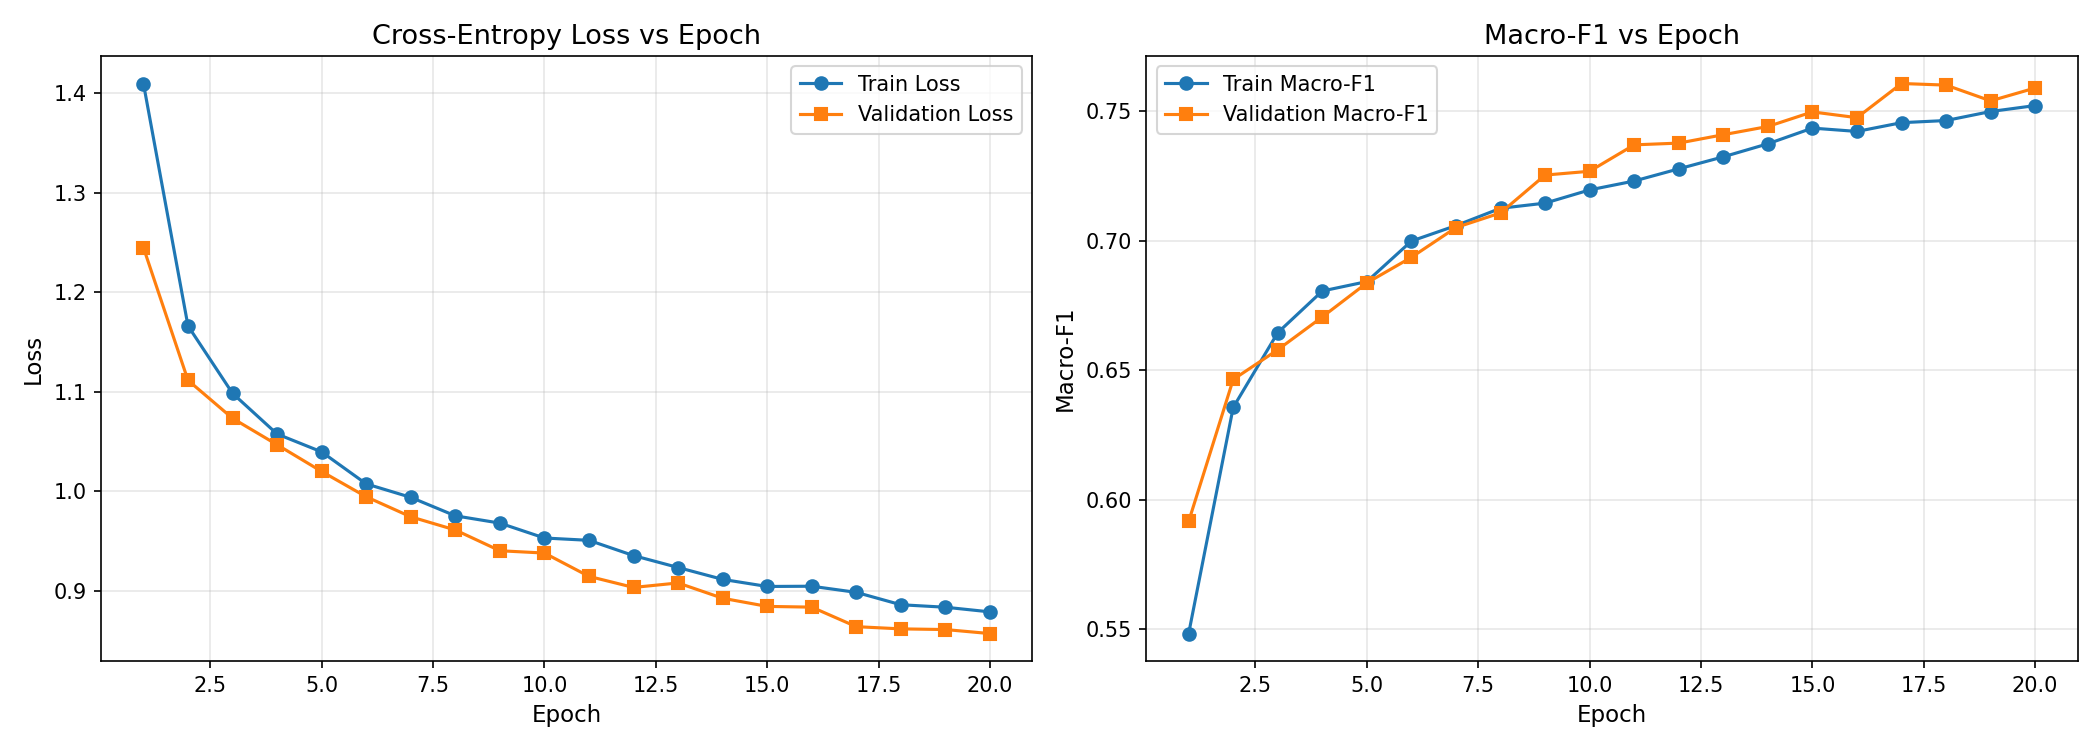


slide_artifact_heatmap.png


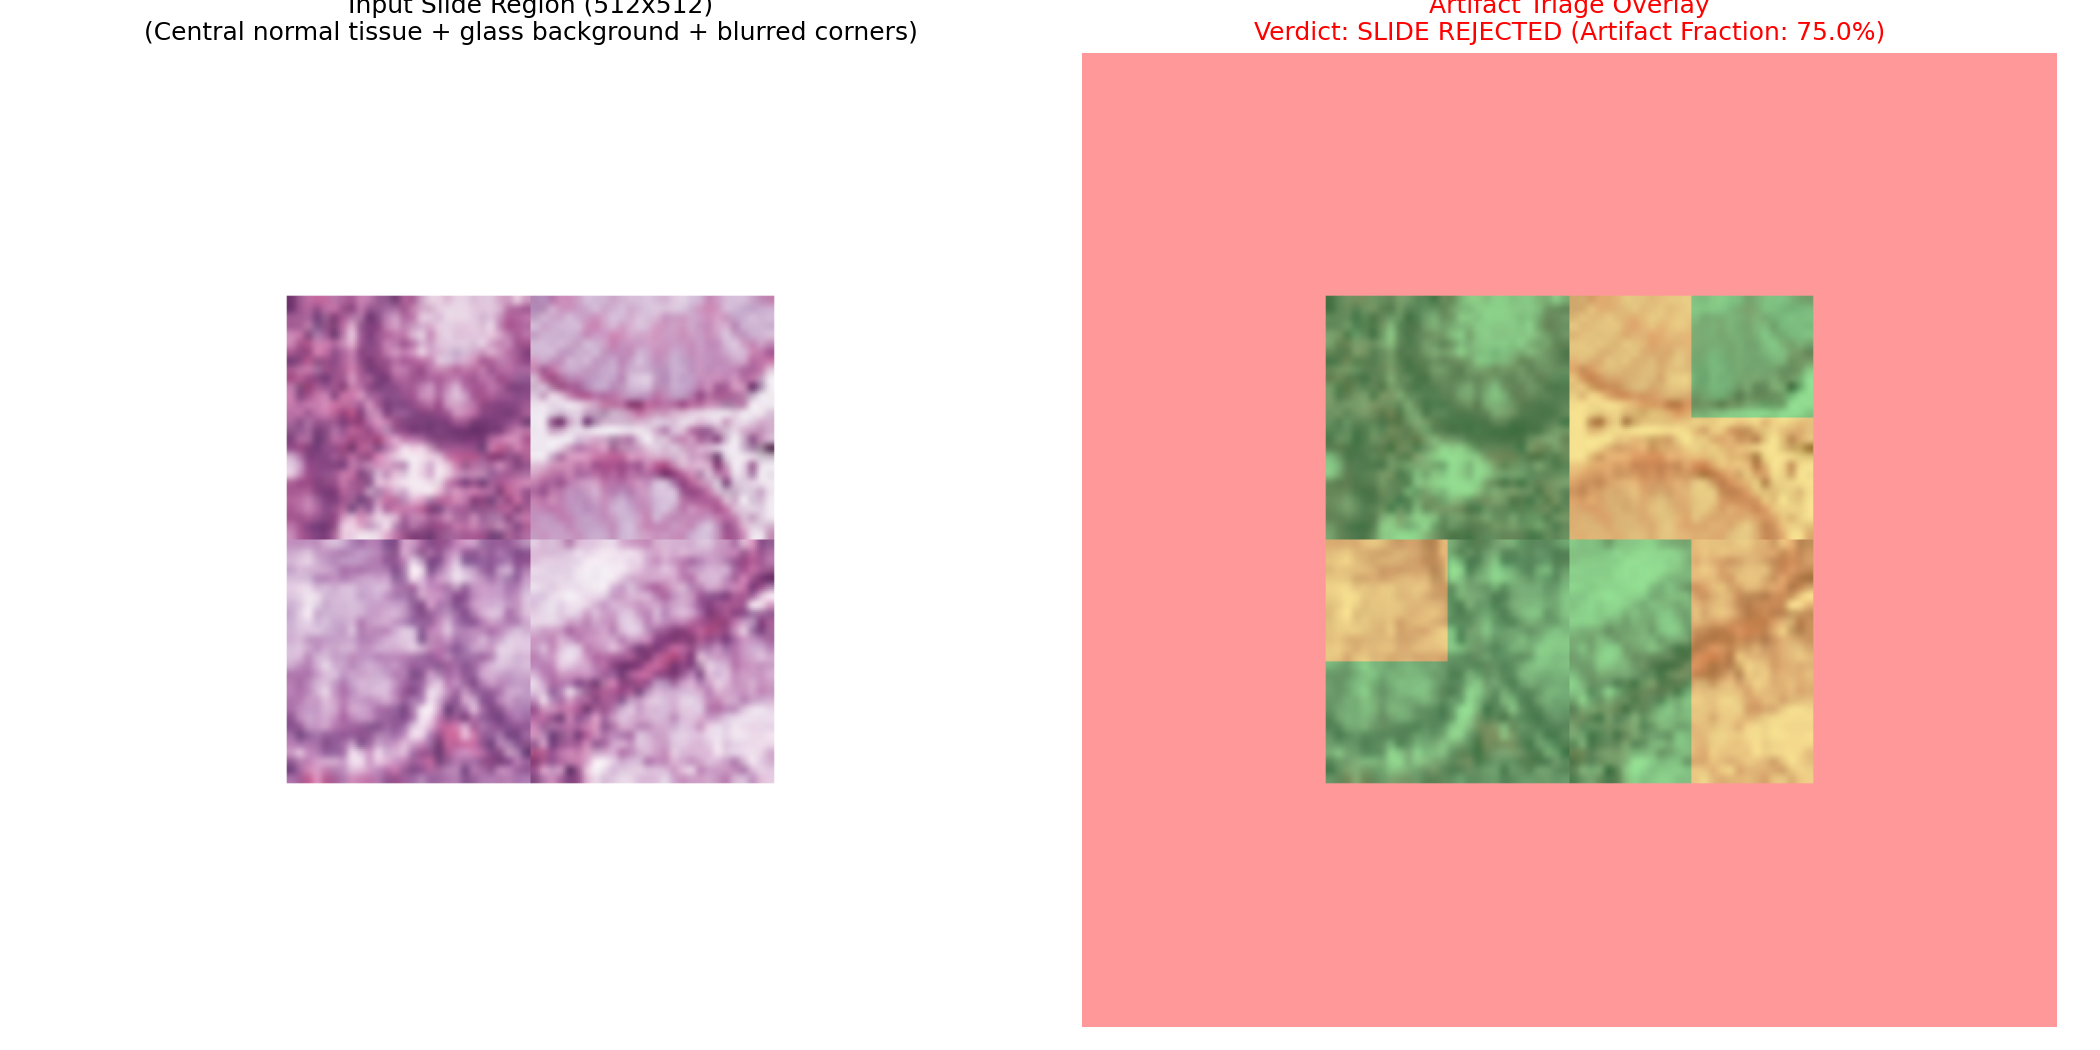


roc_curve.png


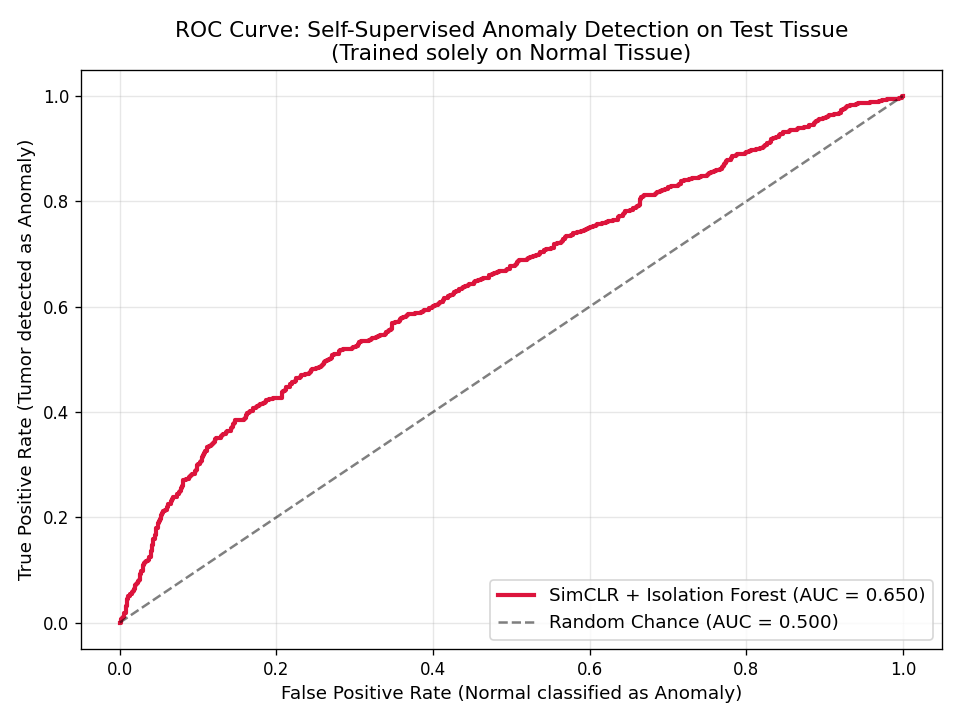


score_distribution.png


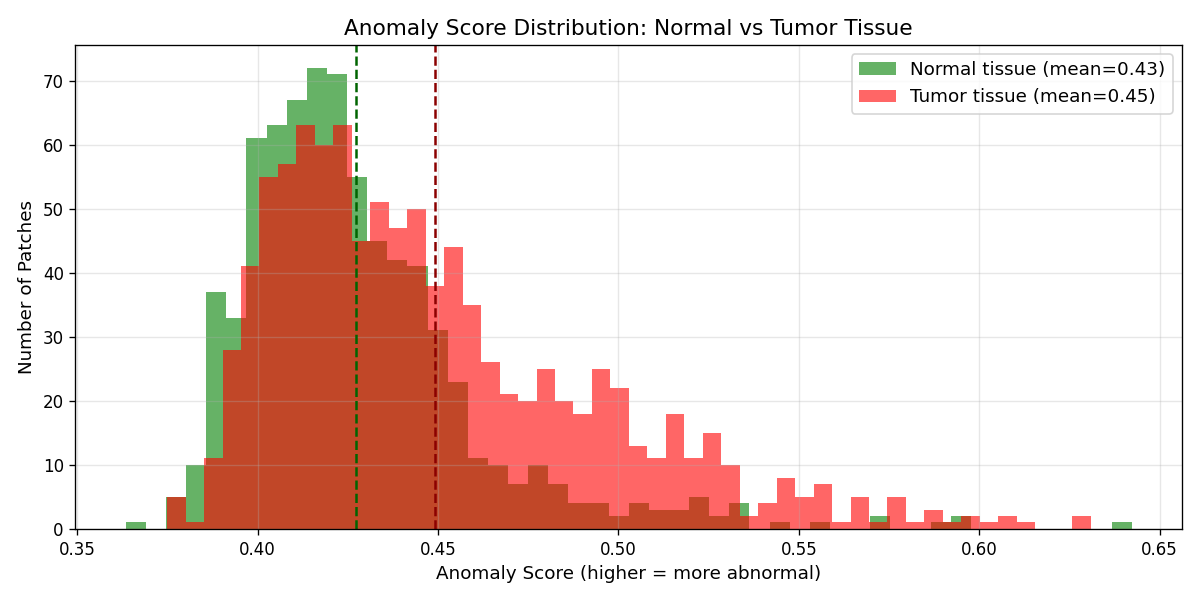


anomaly_heatmap.png


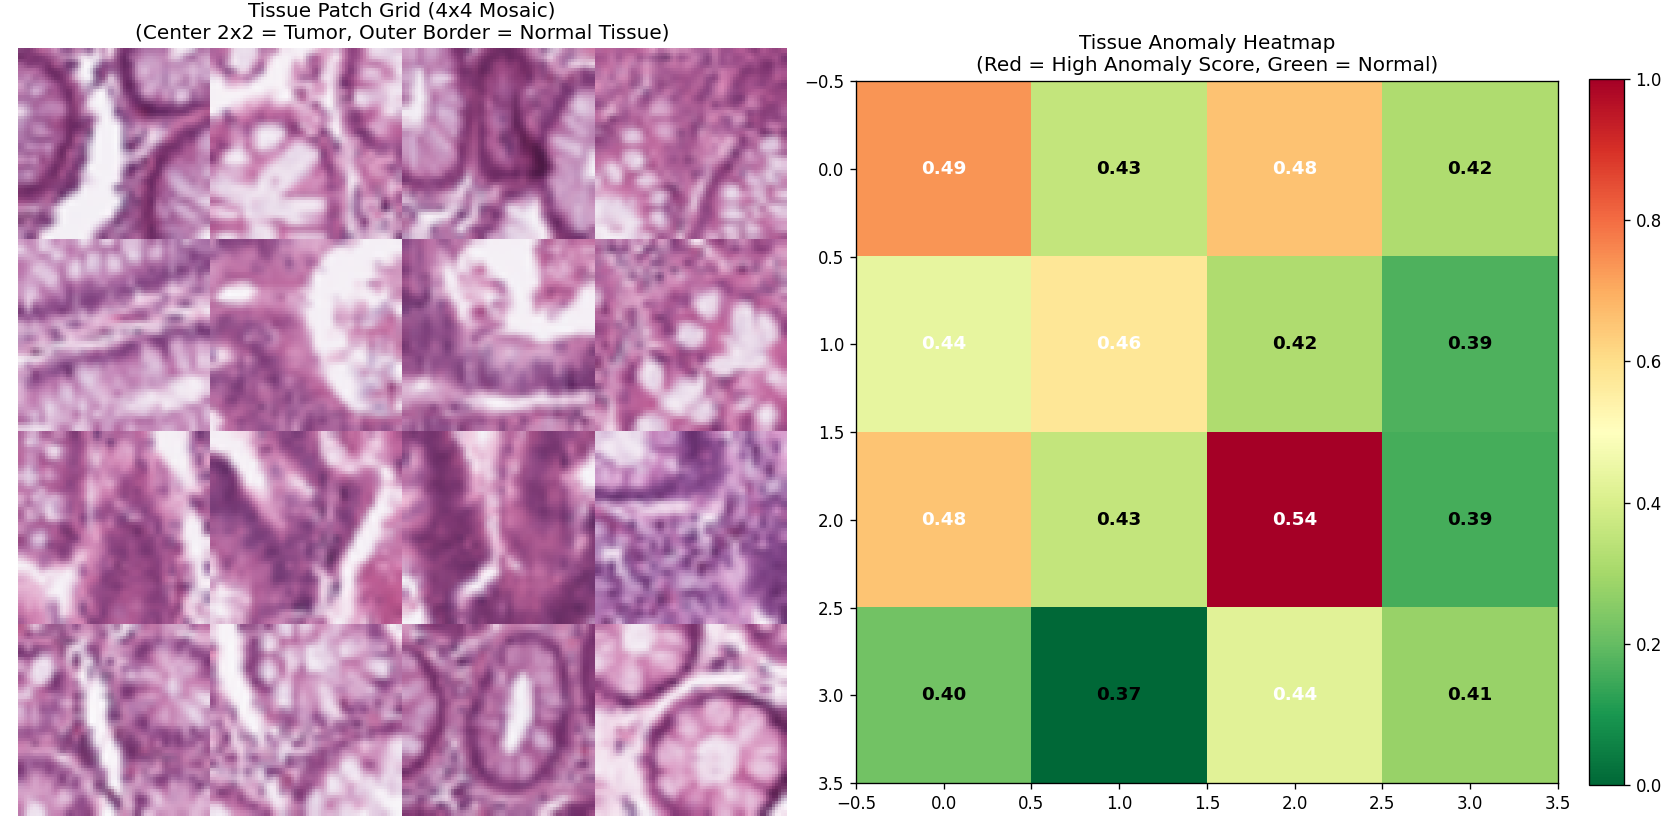


test_set_showcase.png


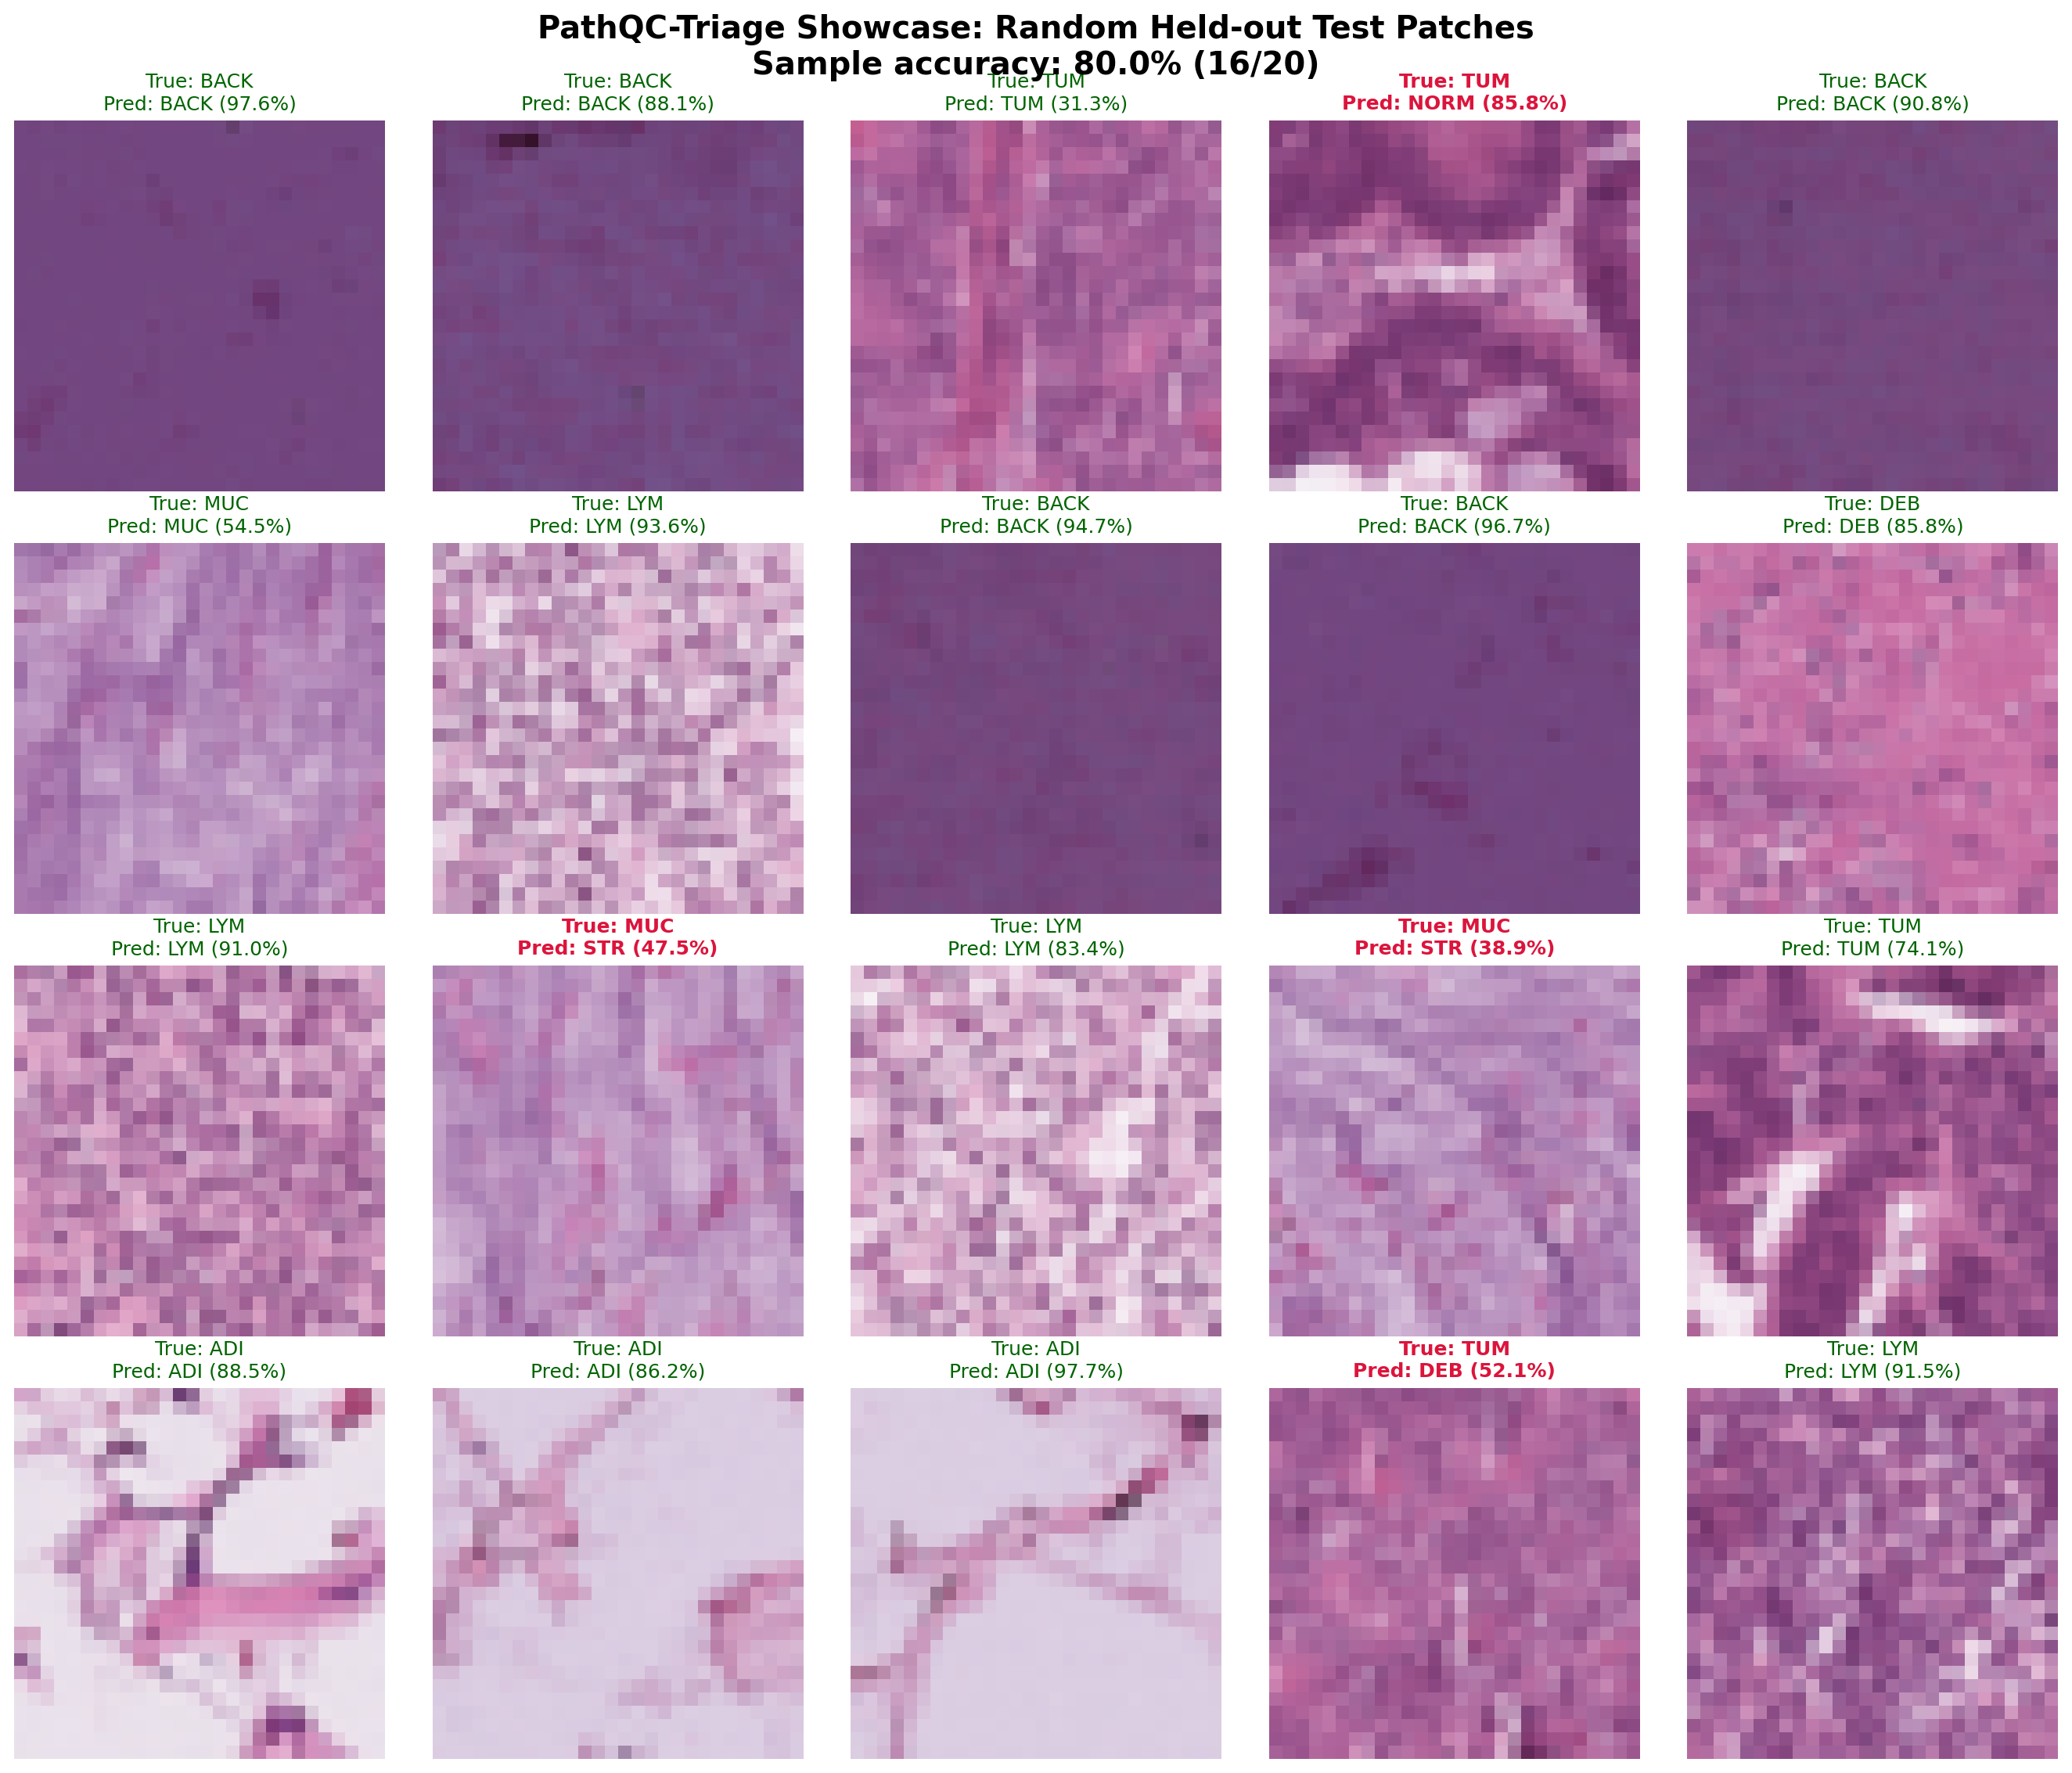

In [40]:
from IPython.display import display, Image as NotebookImage

artifact_names = [
    "best_artifact_model.pth", "simclr_encoder.pth", "anomaly_detector.pkl",
    "stage1_confusion_matrix.png", "stage1_training_curves.png",
    "stage1_class_metrics.png", "dataset_distribution_and_samples.png",
    "slide_artifact_heatmap.png", "roc_curve.png", "score_distribution.png",
    "anomaly_precision_recall_boxplot.png", "anomaly_heatmap.png",
    "test_set_showcase.png",
]
print(f"Output directory: {OUTPUT_DIR.resolve()}")
for name in artifact_names:
    path = OUTPUT_DIR / name
    print(f"{'[FOUND]' if path.exists() else '[NOT FOUND]'} {path}")

for name in artifact_names:
    path = OUTPUT_DIR / name
    if path.suffix.lower() == ".png" and path.exists():
        print(f"\n{name}")
        display(NotebookImage(filename=str(path)))

